<a href="https://colab.research.google.com/github/duong2006-hue/Kh-i/blob/main/b%E1%BA%A3n_nh%C3%A1p_ch%C3%ADnh_3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Báo cáo Phân tích Dữ liệu Vỡ nợ Khoản vay (Loan Default Dataset)

## Nguồn dữ liệu và Bối cảnh bài toán
- **Tên bộ dữ liệu:** Loan Default Dataset (tác giả: Yasser H. trên nền tảng Kaggle).
- **Đường dẫn gốc (URL):** `https://www.kaggle.com/datasets/yasserh/loan-default-dataset`
- **Quy mô dữ liệu:** Gồm **148,670 hồ sơ vay mua bất động sản** với **34 cột thuộc tính** trong năm 2019 (bao gồm các thông tin nhân khẩu học, thu nhập, giá trị tài sản thế chấp, cấu trúc khoản vay và lịch sử tín dụng).
- **Cấu trúc file:** Dữ liệu được đọc từ 1 file duy nhất là `Loan_Default.csv`, không có bảng nào khác để gộp (xem mục 1.3).
- **Biến mục tiêu (`Status`):** Biến nhị phân phản ánh trạng thái khoản vay (`0`: Trả nợ bình thường, `1`: Vỡ nợ / Default).

In [ ]:
# Khai báo các thư viện phục vụ xử lý dữ liệu và vẽ biểu đồ
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Tải dữ liệu Loan Default từ Kaggle về máy
import kagglehub

path = kagglehub.dataset_download("yasserh/loan-default-dataset")
print("Path to dataset files:", path)

Using Colab cache for faster access to the 'loan-default-dataset' dataset.
Path to dataset files: /kaggle/input/loan-default-dataset


In [ ]:
# Thiết lập kích thước mặc định và màu sắc cho các biểu đồ
plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
BLUE = "#2a78d6"
ORANGE = "#eb6834"

**Giải thích code & Đối chiếu Slide bài giảng (Khởi tạo & Cấu hình):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học |  |
| :--- | :--- | :--- | :--- |
| `import pandas as pd`<br>`import numpy as np`<br>`import matplotlib.pyplot as plt`<br>`import seaborn as sns` | Nhập 4 thư viện cốt lõi: xử lý dữ liệu bảng (`pandas`), tính toán mảng số (`numpy`), vẽ đồ thị cơ bản (`matplotlib`) và đồ thị thống kê nâng cao (`seaborn`). | - **Tuần 01 (Bài giảng 1):** Trang 14.<br>- **Tuần 04 (Bài giảng 3):** Quy ước import `np` và `pd` (Trang 1, 13).<br>- **Tuần 12 (Bài giảng 7):** Trang 13, 32. |
| `import kagglehub`<br>`kagglehub.dataset_download(...)` | Tải tự động bộ dữ liệu Loan Default từ Kaggle về bộ nhớ đệm của máy ảo Google Colab. | *Không có trong slide* (Slide Tuần 05, 07, 11 hướng dẫn tải từ GitHub URL, Google Drive hoặc giải nén vào thư mục `data/`). |
| `plt.rcParams["figure.figsize"] = (8, 4)` | Thiết lập kích thước mặc định toàn cục (rộng 8, cao 4 inch) cho tất cả biểu đồ thông qua từ điển cấu hình `plt.rcParams`. | - **Tuần 12 (Bài giảng 7):** Mục *Cấu hình matplotlib* với từ điển `plt.rcParams` (Trang 26).<br>- **Tuần 13 (Thực hành 7):** Bài 1.4. |
| `plt.rcParams["axes.spines.top/right"] = False` | Ẩn đường viền khung phía trên (`top`) và bên phải (`right`) của biểu đồ để đồ thị thoáng, giảm nhiễu thị giác. | - **Tuần 12 (Bài giảng 7):** Nguyên tắc thiết kế biểu đồ rõ ràng (Trang 3) và cấu hình thành phần `axes` trong `plt.rcParams` (Trang 26). |

---
# Giai đoạn 1 — Thu thập và kiểm tra dữ liệu ban đầu

In [ ]:
# Đọc dữ liệu từ file CSV và in ra số dòng, số cột cùng 5 dòng đầu tiên
import os

df = pd.read_csv(os.path.join(path, "Loan_Default.csv"))
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
df.head()

Rows: 148670
Columns: 34


,ID,year,loan_limit,Gender,approv_in_adv,loan_type,loan_purpose,Credit_Worthiness,open_credit,business_or_commercial,...,credit_type,Credit_Score,co-applicant_credit_type,age,submission_of_application,LTV,Region,Security_Type,Status,dtir1
0,24890,2019,cf,Sex Not Available,nopre,type1,p1,l1,nopc,nob/c,...,EXP,758,CIB,25-34,to_inst,98.728814,south,direct,1,45.0
1,24891,2019,cf,Male,nopre,type2,p1,l1,nopc,b/c,...,EQUI,552,EXP,55-64,to_inst,NaN,North,direct,1,NaN
2,24892,2019,cf,Male,pre,type1,p1,l1,nopc,nob/c,...,EXP,834,CIB,35-44,to_inst,80.019685,south,direct,0,46.0
3,24893,2019,cf,Male,nopre,type1,p4,l1,nopc,nob/c,...,EXP,587,CIB,45-54,not_inst,69.376900,North,direct,0,42.0
4,24894,2019,cf,Joint,pre,type1,p1,l1,nopc,nob/c,...,CRIF,602,EXP,25-34,not_inst,91.886544,North,direct,0,39.0


**Giải thích code & Đối chiếu Slide bài giảng (Đọc dữ liệu ban đầu):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `import os`<br>`os.path.join(path, "Loan_Default.csv")` | Ghép đường dẫn thư mục `path` với tên file `"Loan_Default.csv"` để đọc file chính xác trên mọi hệ điều hành. | - **Tuần 06 (Bài giảng 4):** Có sử dụng `import os` ở cuối bài (Trang 16). | **Mở rộng nhỏ từ `import os` (Tuần 06)** |
| `df = pd.read_csv(...)` | Đọc dữ liệu từ tệp văn bản phân tách bằng dấu phẩy (CSV) vào cấu trúc bảng DataFrame `df`. | - **Tuần 06 (Bài giảng 4):** Mục *Đọc dữ liệu CSV cơ bản* (`pd.read_csv`, Trang 1–2). | **Có trong slide** |
| `df.shape[0]`, `df.shape[1]` | Trả về số lượng hàng (`shape[0]`) và số lượng cột (`shape[1]`) của bảng dữ liệu. | - **Tuần 04 (Bài giảng 3):** Thuộc tính `.shape` (Trang 2).<br>- **Tuần 09 (Thực hành 5):** Bài 1.2 (Trang 2). | **Có trong slide** |
| `df.head()` | Hiển thị 5 dòng đầu tiên của DataFrame để quan sát cấu trúc và các giá trị mẫu. | - **Tuần 04 (Bài giảng 3):** Mục *DataFrame* — phương thức `.head()` (Trang 15). | **Có trong slide** |

**Nhận định kết quả:**
- Bộ dữ liệu gốc gồm **148,670 dòng** (hồ sơ vay) và **34 cột** thuộc tính. Quan sát 5 dòng đầu tiên đã thấy xuất hiện các giá trị khuyết (`NaN`) ở cột `LTV`, `dtir1` và nhãn `"Sex Not Available"` ở cột `Gender`.

## 1.1. Kiểm tra kiểu dữ liệu (Data types)

In [ ]:
# Kiểm tra kiểu dữ liệu (dtypes) và số lượng giá trị không trống của từng cột
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 148670 entries, 0 to 148669
Data columns (total 34 columns):
 #   Column                     Non-Null Count   Dtype  
---  ------                     --------------   -----  
 0   ID                         148670 non-null  int64  
 1   year                       148670 non-null  int64  
 2   loan_limit                 145326 non-null  object 
 3   Gender                     148670 non-null  object 
 4   approv_in_adv              147762 non-null  object 
 5   loan_type                  148670 non-null  object 
 6   loan_purpose               148536 non-null  object 
 7   Credit_Worthiness          148670 non-null  object 
 8   open_credit                148670 non-null  object 
 9   business_or_commercial     148670 non-null  object 
 10  loan_amount                148670 non-null  int64  
 11  rate_of_interest           112231 non-null  float64
 12  Interest_rate_spread       112031 non-null  float64
 13  Upfront_charges            10

In [ ]:
# Đếm số lượng hồ sơ theo từng nhãn Status (0: Không vỡ nợ, 1: Vỡ nợ) và tính tỷ lệ vỡ nợ ban đầu
print(df["Status"].value_counts())
print("Default rate:", round(df["Status"].mean() * 100, 1), "%")

Status
0    112031
1     36639
Name: count, dtype: int64
Default rate: 24.6 %


**Giải thích code & Đối chiếu Slide bài giảng (Mục 1.1 - Kiểu dữ liệu & Biến mục tiêu):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học |  |
| :--- | :--- | :--- | :--- |
| `df.info()` | In thông tin tổng quan của DataFrame: tổng số dòng, tên các cột, số lượng giá trị không rỗng (`Non-Null Count`) và kiểu dữ liệu (`float64`, `int64`, `object`). | - **Tuần 05 (Thực hành 3):** Bài 2.6.<br>- **Tuần 15 (Thực hành 8):** Mục *Tìm hiểu dữ liệu* (`df_housing.info()`, `df_cancer.info()`, Trang 2, 10). |
| `df["Status"].value_counts()` | Đếm số lượng hồ sơ theo từng nhãn của biến mục tiêu `Status` (`0`: Không vỡ nợ, `1`: Vỡ nợ). | - **Tuần 01 (Bài giảng 1):** Kiểm tra phân phối biến mục tiêu mất cân bằng (Trang 25).<br>- **Tuần 15 (Thực hành 8):** Kiểm tra sự cân bằng lớp (Trang 10). |
| `round(df["Status"].mean() * 100, 1)` | Tính tỷ lệ vỡ nợ trung bình (%) trên toàn bộ dữ liệu gốc (vì `Status` chỉ nhận giá trị `0` và `1` nên trung bình cộng chính là tỷ lệ của nhãn `1`). | - **Tuần 04 (Bài giảng 3):** Các phương thức thống kê toán học `.mean()` (Trang 8–9). |

**Nhận định kết quả:**
- Bảng dữ liệu gồm **8 cột số thực (`float64`)**, **5 cột số nguyên (`int64`)** và **21 cột chuỗi phân loại (`object`)**.
- Toàn bộ tập dữ liệu gốc có **112,031** hồ sơ không vỡ nợ (`Status = 0`) và **36,639** hồ sơ vỡ nợ (`Status = 1`), tương ứng tỷ lệ vỡ nợ ban đầu là **24.6%** (bài toán phân loại nhị phân có mất cân bằng lớp).

## 1.2. Kiểm tra dữ liệu bị thiếu (Missing values)

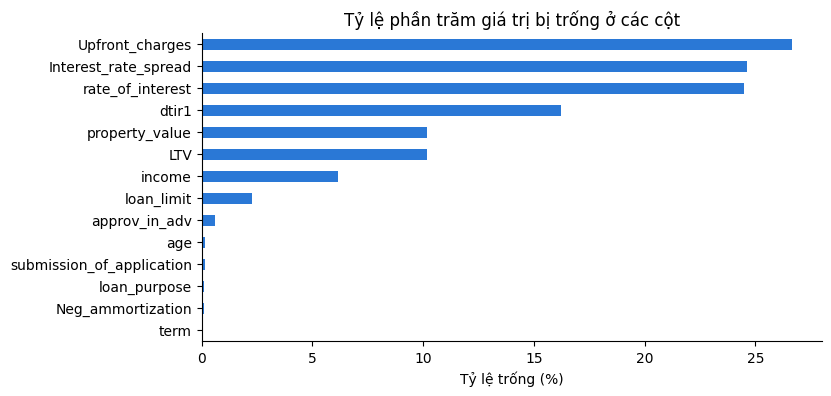

Upfront_charges              26.7
Interest_rate_spread         24.6
rate_of_interest             24.5
dtir1                        16.2
property_value               10.2
LTV                          10.2
income                        6.2
loan_limit                    2.2
approv_in_adv                 0.6
Neg_ammortization             0.1
loan_purpose                  0.1
age                           0.1
submission_of_application     0.1
term                          0.0
dtype: float64


In [ ]:
# Tính tỷ lệ phần trăm dữ liệu bị thiếu ở các cột và lọc ra những cột có ô trống (> 0%)
missing = df.isnull().mean() * 100
missing = missing[missing > 0].sort_values()

# Vẽ biểu đồ thanh ngang thể hiện tỷ lệ thiếu dữ liệu của từng cột
missing.plot(kind="barh", color=BLUE)
plt.title("Tỷ lệ phần trăm giá trị bị trống ở các cột")
plt.xlabel("Tỷ lệ trống (%)")
plt.show()

# In bảng tỷ lệ phần trăm thiếu dữ liệu theo thứ tự giảm dần
print(missing.round(1).sort_values(ascending=False))

**Giải thích code & Đối chiếu Slide bài giảng (Mục 1.2 - Kiểm tra dữ liệu thiếu):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `missing = df.isnull().mean() * 100` | Phát hiện ô trống bằng `.isnull()` (`True=1, False=0`) rồi tính trung bình nhân 100 để ra tỷ lệ % thiếu của từng cột. | - **Tuần 08 (Bài giảng 5):** Mục *Các phương thức phát hiện dữ liệu thiếu* (`isna() / isnull()`, tính `missing_percent`, Trang 2 & 5). | **Có trong slide** |
| `missing[missing > 0].sort_values()` | Dùng chỉ số kiểu logical (Boolean Indexing) lọc riêng các cột có tỷ lệ trống `> 0%` và sắp xếp theo thứ tự tăng dần. | - **Tuần 04 (Bài giảng 3):** Chỉ số kiểu logical / Boolean Indexing (Trang 5).<br>- **Tuần 08 (Bài giảng 5):** `missing_percent[missing_percent > 0]` (Trang 5). | **Có trong slide** |
| `missing.plot(kind="barh", color=BLUE)` | Vẽ biểu đồ thanh ngang (`barh`) cho đối tượng Series để dễ đọc tên các cột dài. | - **Tuần 12 (Bài giảng 7):** Nguyên tắc chọn `barh` khi tên danh mục dài (Trang 6) và tham số `kind="barh"` của `Series.plot` (Trang 27). | **Có trong slide** |

**Nhận định kết quả:**
- Có **14/34 cột** bị khuyết dữ liệu, dẫn đầu là `Upfront_charges` (`26.7%`), `Interest_rate_spread` (`24.6%`), `rate_of_interest` (`24.5%`), `dtir1` (`16.2%`), `property_value` (`10.2%`), `LTV` (`10.2%`) và `income` (`6.2%`).
- Đáng chú ý, tỷ lệ thiếu của `Interest_rate_spread` (`24.6%`) và `rate_of_interest` (`24.5%`) ngang bằng với tỷ lệ vỡ nợ của toàn tập dữ liệu (`24.6%`), báo hiệu dữ liệu thiếu không ngẫu nhiên cần kiểm tra rò rỉ dữ liệu ở Giai đoạn 2.

## 1.3. Kiểm tra tính nhất quán giữa các file dữ liệu


Tại sao: Nếu dữ liệu nằm ở nhiều bảng, khóa chính/khóa ngoại lệch nhau sẽ làm mất hoặc nhân đôi hồ sơ khi gộp bảng.
Mục đích: Xác nhận bộ dữ liệu có cần gộp bảng qua khóa chính/khóa ngoại hay không, và mã `ID` có dùng được làm khóa chính không.
Phương pháp: Liệt kê các file trong thư mục dữ liệu, rồi kiểm tra cột `ID` có trống hoặc trùng hay không.


In [ ]:
# Liệt kê các file trong thư mục dữ liệu để xác nhận cấu trúc file (có cần gộp bảng qua khóa chính/khóa ngoại hay không)
files = os.listdir(path)
print("Các file trong thư mục dữ liệu:", files)
print("Số file CSV:", sum(f.endswith(".csv") for f in files))

# Kiểm tra khóa chính của bảng duy nhất: ID phải không trống và không trùng
print("ID không trống:", df["ID"].notnull().all())
print("ID không trùng (khóa chính hợp lệ):", df["ID"].is_unique)

Các file trong thư mục dữ liệu: ['Loan_Default.csv']
Số file CSV: 1
ID không trống: True
ID không trùng (khóa chính hợp lệ): True


Giải thích code:

- `os.listdir(path)`: liệt kê tên các file có trong thư mục dữ liệu đã tải.
- `df["ID"].notnull().all()` và `df["ID"].is_unique`: kiểm tra mã `ID` không có ô trống và không có giá trị lặp.

**Nhận định kết quả:**
- Notebook chỉ sử dụng 1 file `Loan_Default.csv` và không thực hiện phép gộp bảng nào, nên không phát sinh khóa ngoại. Việc kiểm tra tính nhất quán giữa các file được xác nhận là **không áp dụng** cho bộ dữ liệu này.
- Cột `ID` không có ô trống (148,670/148,670 dòng, theo `df.info()` ở mục 1.1) và không có giá trị trùng, nên dùng được làm khóa chính để xác định từng hồ sơ vay.


---
# Giai đoạn 2 — Tiền xử lý và làm sạch dữ liệu
## 2.1. Kiểm tra dòng trùng lặp và sai định dạng

Tại sao: Một hồ sơ bị nhập hai lần sẽ bị đếm hai lần, làm lệch mọi tỷ lệ tính sau này. Ngoài ra, cột chữ có thể bị ghi sai chính tả hoặc viết hoa/thường không thống nhất.
Mục đích: Xác nhận không có hồ sơ trùng, và tìm các giá trị bất thường trong cột chữ.
Phương pháp: Đếm số dòng trùng theo ba cách: trùng toàn dòng, trùng mã ID, và trùng khi bỏ cột ID. In các giá trị khác nhau của ba cột `year`, `Region`, `Security_Type` để kiểm tra bằng mắt.

In [ ]:
# Kiểm tra số dòng trùng lặp trên toàn bảng, trùng mã ID, và trùng khi đã bỏ cột ID
print("Duplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["ID"].duplicated().sum())
print("Duplicate rows (không tính ID):", df.drop(columns="ID").duplicated().sum())

# Kiểm tra các giá trị duy nhất trong các cột phân loại để phát hiện lỗi chính tả hoặc viết hoa/thường
print("Values in 'year':", df["year"].unique())
print("Values in 'Region':", df["Region"].unique())
print("Values in 'Security_Type':", df["Security_Type"].unique())

Duplicate rows: 0
Duplicate IDs: 0
Duplicate rows (không tính ID): 0
Values in 'year': [2019]
Values in 'Region': ['south' 'North' 'central' 'North-East']
Values in 'Security_Type': ['direct' 'Indriect']


**Giải thích code & Đối chiếu Slide bài giảng (Kiểm tra trùng lặp & sai định dạng):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `df.duplicated().sum()`<br>`df["ID"].duplicated().sum()` | Kiểm tra từng hàng xem có giống hệt hàng phía trên không và đếm tổng số dòng/mã ID bị trùng lặp. | - **Tuần 08 (Bài giảng 5):** Mục *Xử lý dữ liệu trùng lặp* (`duplicated().sum()`, Trang 9–10).<br>- **Tuần 09 (Thực hành 5):** Phần 2 - Bài 2.1. | **Có trong slide** |
| `df.drop(columns="ID").duplicated().sum()` | Bỏ cột mã định danh `ID` rồi mới kiểm tra trùng lặp để bắt trường hợp một hồ sơ bị nhập 2 lần với 2 mã `ID` khác nhau. | - **Tuần 04 & 15:** Xóa cột bằng `.drop()` (Tuần 04 Trang 17; Tuần 15 Trang 5). | **Có trong slide** |
| `df["year"].unique()`<br>`df["Region"].unique()`<br>`df["Security_Type"].unique()` | Trả về mảng các giá trị duy nhất xuất hiện trong từng cột phân loại để phát hiện lỗi chính tả hoặc viết hoa/thường. | - **Tuần 04 (Bài giảng 3):** Hàm `np.unique()` (Trang 10) và phương thức `.unique()` của Index/Series trong Pandas (Trang 17). | **Có trong slide** |

**Nhận định kết quả:**
- Bộ dữ liệu có `0` dòng trùng lặp và `0` mã `ID` trùng (kể cả khi đã bỏ cột `ID`).
- Cột `year` chỉ có duy nhất 1 giá trị là `2019` nên không mang thông tin phân biệt.
- Cột `Region` bị viết không thống nhất chữ hoa/thường (`'south'`, `'North'`, `'central'`, `'North-East'`).
- Cột `Security_Type` có giá trị bị gõ sai chính tả là `'Indriect'` (đúng phải là `'Indirect'`).

Tại sao: Hai cột ghi cùng một thông tin thì giữ cả hai là thừa, và khi phân tích sẽ bị lặp kết quả.
Mục đích: Kiểm tra xem loại khoản vay và mục đích kinh doanh có phải là một thông tin ghi hai lần không.
Phương pháp: Lập bảng đếm chéo giữa hai cột.

In [ ]:
# Lập bảng tần số chéo (crosstab) kiểm tra sự trùng lặp thông tin giữa loan_type và business_or_commercial
pd.crosstab(df["loan_type"], df["business_or_commercial"])

business_or_commercial,b/c,nob/c
loan_type,,
type1,0,113173
type2,20762,0
type3,0,14735


Giải thích code:

- `pd.crosstab(a, b)`: bảng đếm chéo, mỗi ô là số hồ sơ có đồng thời giá trị ở hàng và ở cột.
- Ô bằng 0 nghĩa là hai giá trị đó không bao giờ xuất hiện cùng nhau.

**Nhận định kết quả:**
- Toàn bộ 20,762 hồ sơ `type2` đều nằm ở nhóm `b/c` (vay thương mại), còn 100% hồ sơ `type1` và `type3` đều nằm ở nhóm `nob/c`. Như vậy cột `business_or_commercial` lặp lại hoàn toàn thông tin của nhóm `type2` trong cột `loan_type`, nên ta chỉ cần giữ lại `loan_type` và xóa `business_or_commercial`.

Tại sao: Chữ viết sai hoặc viết không thống nhất làm một nhóm bị tách thành hai. Ô ghi “Sex Not Available” trông như có dữ liệu nhưng thực chất là thiếu thông tin. Một số cột không giúp phân biệt người vỡ nợ với người trả được.
Mục đích: Làm sạch các giá trị chữ, và bỏ những cột không mang thông tin.
Phương pháp: Tạo bản sao để không đụng vào dữ liệu gốc. Sửa chữ sai, thống nhất cách viết hoa, đổi tên giá trị thiếu thông tin. Bỏ ID (mã số), year (một giá trị duy nhất) và business_or_commercial (theo bảng chéo loan_type × business_or_commercial ở ngay bước trên).

In [ ]:
# Tạo bản sao dữ liệu để xử lý làm sạch mà không làm thay đổi bảng gốc df
clean = df.copy()

# Chuẩn hóa chữ hoa/thường cho cột Region, sửa lỗi chính tả cột Security_Type và đổi tên nhóm khuyết giới tính
clean["Region"] = clean["Region"].str.title()
clean["Security_Type"] = clean["Security_Type"].replace("Indriect", "Indirect")
clean["Gender"] = clean["Gender"].replace("Sex Not Available", "Không rõ")

# Xóa các cột không mang thông tin phân biệt (ID, year) và cột bị trùng thông tin (business_or_commercial)
clean = clean.drop(columns=["ID", "year", "business_or_commercial"])

print(clean["Region"].unique())
print("Columns left:", clean.shape[1])
print("Số hồ sơ Gender = 'Không rõ':", (clean["Gender"] == "Không rõ").sum())

['South' 'North' 'Central' 'North-East']
Columns left: 31
Số hồ sơ Gender = 'Không rõ': 37659


**Giải thích code & Đối chiếu Slide bài giảng (Làm sạch chuỗi ký tự & Xóa cột thừa):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `clean = df.copy()` | Tạo bản sao độc lập của DataFrame để mọi thao tác chỉnh sửa trên `clean` không làm thay đổi bảng gốc `df`. | - **Tuần 04 (Bài giảng 3):** Phương thức `.copy()` (Trang 4).<br>- **Tuần 08 (Bài giảng 5):** Trang 4. | **Có trong slide** |
| `clean["Region"].str.title()` | Sử dụng Pandas String Accessor `.str.title()` để viết hoa chữ cái đầu mỗi từ (`'south'` -> `'South'`, `'central'` -> `'Central'`). | - **Tuần 08 (Bài giảng 5):** Mục *Xử lý chuỗi ký tự - Pandas String Accessor (`.str`)*: Bảng phương thức `.str.title()` (Trang 13–14).<br>- **Tuần 09 (Thực hành 5):** Bài 4.1. | **Có trong slide** |
| `.replace("Indriect", "Indirect")`<br>`.replace("Sex Not Available", "Không rõ")` | Thay thế giá trị bị gõ sai chính tả bằng từ đúng và đổi tên nhãn thiếu thông tin giới tính thành nhóm `"Không rõ"`. | - **Tuần 08 (Bài giảng 5):** Các vấn đề thường gặp với dữ liệu chuỗi (lỗi chính tả, không nhất quán định dạng) và phương thức `.replace()` (Trang 13). | **Có trong slide** |
| `clean.drop(columns=["ID", "year", "business_or_commercial"])` | Loại bỏ 3 cột không mang thông tin phân biệt hoặc bị trùng lặp hoàn toàn. | - **Tuần 04 & 15:** Xóa cột bằng `.drop()` (Tuần 04 Trang 17; Tuần 15 Trang 5). | **Có trong slide** |

**Nhận định kết quả:**
- Sau khi xóa 3 cột (`ID`, `year`, `business_or_commercial`), bảng dữ liệu còn lại `31` cột và cột `Region` đã đồng nhất thành 4 khu vực chuẩn (`['South', 'North', 'Central', 'North-East']`).
- Giá trị `"Sex Not Available"` xuất hiện ở 37,659 hồ sơ là nhóm khách hàng không cung cấp thông tin giới tính, nên được giữ thành nhóm `"Không rõ"` riêng biệt.

## 2.2. Kiểm tra rò rỉ dữ liệu (Data Leakage) và xử lý giá trị bị thiếu

Tại sao: Trước khi lấp ô trống, phải biết ô trống có xảy ra ngẫu nhiên không. Nếu ô trống tập trung ở nhóm vỡ nợ, lấp vào sẽ tạo ra dữ liệu giả và làm sai kết quả phân tích.
Mục đích: So tỷ lệ bị trống của từng cột giữa hai nhóm trả nợ tốt (`Status = 0`) và vỡ nợ (`Status = 1`).
Phương pháp: Chia hồ sơ theo `Status`, tính tỷ lệ ô trống của 6 cột ở mỗi nhóm rồi vẽ biểu đồ thanh ngang so sánh.

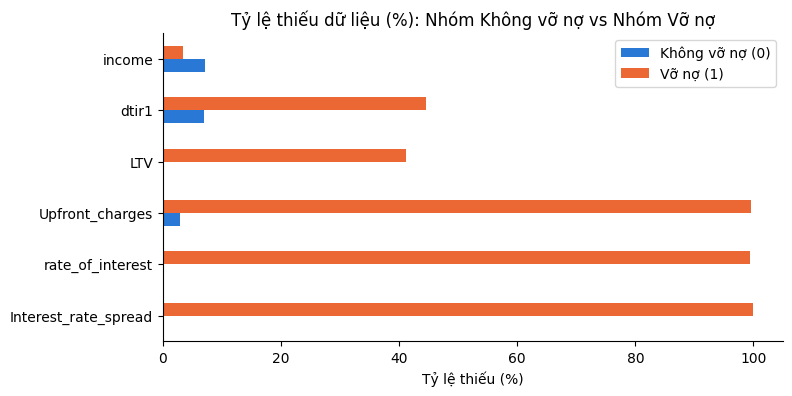

,Không vỡ nợ (0),Vỡ nợ (1)
Interest_rate_spread,0.0,100.0
rate_of_interest,0.0,99.5
Upfront_charges,2.8,99.6
LTV,0.0,41.2
dtir1,7.0,44.5
income,7.1,3.4


In [ ]:
# Danh sách 6 cột quan trọng có nhiều giá trị bị thiếu cần kiểm tra theo nhóm Status
cols = ["Interest_rate_spread", "rate_of_interest", "Upfront_charges", "LTV", "dtir1", "income"]

# Tính tỷ lệ phần trăm ô trống của 6 cột riêng cho nhóm Không vỡ nợ (0) và nhóm Vỡ nợ (1)
missing_0 = clean[clean["Status"] == 0][cols].isnull().mean() * 100
missing_1 = clean[clean["Status"] == 1][cols].isnull().mean() * 100

missing_by_status = pd.DataFrame({
    "Không vỡ nợ (0)": missing_0,
    "Vỡ nợ (1)": missing_1
})

# Vẽ biểu đồ so sánh tỷ lệ thiếu dữ liệu giữa hai nhóm để phát hiện rò rỉ dữ liệu (Data Leakage)
missing_by_status.plot(kind="barh", color=[BLUE, ORANGE])
plt.title("Tỷ lệ thiếu dữ liệu (%): Nhóm Không vỡ nợ vs Nhóm Vỡ nợ")
plt.xlabel("Tỷ lệ thiếu (%)")
plt.show()

missing_by_status.round(1)

**Giải thích code & Đối chiếu Slide bài giảng (Phát hiện rò rỉ dữ liệu ở các cột khuyết):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `clean[clean["Status"] == 0][cols].isnull().mean() * 100`<br>`clean[clean["Status"] == 1][cols].isnull().mean() * 100` | Lọc dữ liệu theo từng nhóm `Status` (Boolean Indexing) và tính tỷ lệ % ô trống của 6 cột ở mỗi nhóm. | - **Tuần 04 (Bài giảng 3):** Boolean Indexing (Trang 5).<br>- **Tuần 08 (Bài giảng 5):** Phân loại dữ liệu thiếu có quy luật (MAR / MNAR) gây thiên lệch kết quả (Trang 1–2). | **Có trong slide** |
| `pd.DataFrame({...}).plot(kind="barh", color=[BLUE, ORANGE])` | Ghép 2 Series tỷ lệ thiếu thành bảng DataFrame và vẽ biểu đồ thanh ngang ghép cặp để trực quan hóa sự chênh lệch. | - **Tuần 04 (Bài giảng 3):** Tạo DataFrame từ `dict` của các Series (Trang 15–16).<br>- **Tuần 12 (Bài giảng 7):** Vẽ đồ thị cột nhóm từ DataFrame (`.plot.barh()`, Trang 29). | **Có trong slide** |

**Nhận định kết quả:**
- Ba cột `Interest_rate_spread`, `rate_of_interest` và `Upfront_charges` gần như không thiếu ở nhóm trả được (`0%` – `2.8%`), nhưng lại bị trống tới **99.5% – 100%** ở nhóm vỡ nợ (`Status = 1`).
- Tương tự, cột `LTV` không thiếu (`0.0%`) ở nhóm trả được nhưng thiếu tới `41.2%` ở nhóm vỡ nợ. Điều này chứng tỏ các cột lãi suất/phí thực tế chỉ được hệ thống ngân hàng cập nhật đầy đủ khi khoản vay trả nợ tốt, gây ra hiện tượng **rò rỉ dữ liệu (Data Leakage)** nghiêm trọng.

Tại sao: Cần một bằng chứng đơn giản, dễ hiểu cho thấy ô trống ở cột chênh lệch lãi suất “lộ” sẵn đáp án.
Mục đích: Đo xem chỉ nhìn ô đó có trống hay không thì đoán đúng bao nhiêu phần trăm người vỡ nợ.
Phương pháp: Coi “ô trống” là đoán vỡ nợ, “ô có số” là đoán trả được, rồi so với Status thật.

In [ ]:
# Thử dự đoán Status chỉ dựa vào việc cột Interest_rate_spread có bị trống (1) hay không (0) để chứng minh Data Leakage
guess = clean["Interest_rate_spread"].isnull().astype(int)
accuracy = (guess == clean["Status"]).mean()
print("Accuracy of guessing with only one empty field:", round(accuracy * 100, 2), "%")

Accuracy of guessing with only one empty field: 100.0 %


**Giải thích code & Đối chiếu Slide bài giảng (Chứng minh định lượng Data Leakage):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `guess = clean["Interest_rate_spread"].isnull().astype(int)` | Chuyển mảng boolean của `.isnull()` thành số nguyên (`1` nếu ô trống = đoán vỡ nợ, `0` nếu có số = đoán trả tốt). | - **Tuần 04 (Bài giảng 3):** Chuyển đổi kiểu dữ liệu mảng bằng `.astype()` (Trang 3–4).<br>- **Tuần 08 (Bài giảng 5):** `.isnull()` (Trang 2). | **Có trong slide** |
| `accuracy = (guess == clean["Status"]).mean()` | So sánh kết quả đoán mò theo ô trống với nhãn `Status` thật và lấy trung bình để tính độ chính xác (`Accuracy`). | - **Tuần 01 (Bài giảng 1):** Tính độ chính xác phân loại bằng `np.mean(Y_pred == Y_test)` (Trang 21). | **Có trong slide** |

**Nhận định kết quả:**
- Chỉ cần nhìn xem cột `Interest_rate_spread` có bị bỏ trống hay không (không cần bất kỳ thông tin tài chính nào khác), quy tắc đoán mò này đã trùng khớp **100.0%** với nhãn `Status`. Nếu giữ cột này lại hoặc điền khuyết bằng trung bình/trung vị, mọi phân tích và mô hình học máy sẽ gian lận dựa vào việc đếm ô trống thay vì đánh giá rủi ro thực của khách hàng.

Tại sao: Ngoài ô trống, một giá trị cụ thể trong cột chữ cũng có thể lộ sẵn đáp án.
Mục đích: Kiểm tra xem có loại credit_type nào gắn gần như tuyệt đối với vỡ nợ không.
Phương pháp: Tính tỷ lệ vỡ nợ của từng loại credit_type.

In [ ]:
# Tính tỷ lệ vỡ nợ (%) cho từng loại tổ chức tín dụng (credit_type) để phát hiện nhãn EQUI bị lệch 100%
clean.groupby("credit_type")["Status"].mean().round(4) * 100

,Status
credit_type,
CIB,15.80
CRIF,16.23
EQUI,99.99
EXP,15.99


**Giải thích code & Đối chiếu Slide bài giảng (Kiểm tra rò rỉ ở biến `credit_type`):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `clean.groupby("credit_type")["Status"].mean().round(4) * 100` | Gom nhóm hồ sơ theo từng tổ chức tín dụng (`credit_type`) và tính tỷ lệ phần trăm vỡ nợ trung bình của mỗi nhóm. | - **Tuần 01, 08, 10:** Gom nhóm và tính thống kê `.groupby(...).mean().round()` (Tuần 01 Trang 18; Tuần 10 Trang 5, 15). | **Có trong slide** |

**Nhận định kết quả:**
- Trong khi 3 nhóm `CIB`, `CRIF`, `EXP` có tỷ lệ vỡ nợ rất đồng đều quanh mức `15.8% – 16.23%`, thì riêng nhóm `EQUI` có tỷ lệ vỡ nợ lên tới **99.99%**.
- Tỷ lệ vỡ nợ gần `100%` của `EQUI` khác hẳn ba nhóm còn lại nên đây là dấu hiệu rò rỉ nhãn , nhiều khả năng do nguồn thu thập dữ liệu chứ không phải đặc điểm tự nhiên của khách hàng; vì vậy cột `credit_type` được loại bỏ. Ô đối chiếu bên dưới kiểm tra thêm tỷ lệ thiếu `LTV` và `property_value` theo từng loại `credit_type`.

In [ ]:
# Đối chiếu tỷ lệ ô trống của LTV và property_value theo từng loại credit_type để kiểm chứng nhóm EQUI
print(clean.groupby("credit_type")[["LTV", "property_value"]].apply(lambda g: g.isnull().mean() * 100).round(1))

              LTV  property_value
credit_type                      
CIB           0.0             0.0
CRIF          0.0             0.0
EQUI         98.7            98.7
EXP           0.0             0.0


Giải thích code:

- `groupby("credit_type")[[...]].apply(lambda g: g.isnull().mean() * 100)`: tính phần trăm ô trống của `LTV` và `property_value` trong từng loại `credit_type`.
- Đọc bảng bằng cách so sánh hàng `EQUI` với ba hàng `CIB`, `CRIF`, `EXP`.


**Nhận định kết quả**:
98,7% hồ sơ `EQUI` thiếu `LTV` và `property_value`, trong khi ba loại còn lại không thiếu. Như vậy `EQUI` gần như trùng với nhóm hồ sơ bị loại ở bước lọc `LTV`.

Tại sao: Ba bước kiểm tra ở trên (tỷ lệ thiếu theo Status, đoán bằng ô trống, credit_type) cho thấy 4 cột lộ sẵn đáp án. Ngoài ra, hồ sơ thiếu LTV gần như toàn là người vỡ nợ và thiếu đồng loạt nhiều cột; lấp vào nghĩa là gán số liệu của người trả được cho người vỡ nợ.
Mục đích: Tạo một tập phân tích không còn rò rỉ, dùng chung cho cả Giai đoạn 3.
Phương pháp: Bỏ 4 cột: Interest_rate_spread, rate_of_interest, Upfront_charges, credit_type. Bỏ những hồ sơ không có LTV. Tính lại tỷ lệ vỡ nợ của tập còn lại để làm mức tham chiếu.

In [ ]:
# Xóa 4 cột gây rò rỉ dữ liệu (Data Leakage) và loại bỏ các dòng bị thiếu giá trị LTV
clean = clean.drop(columns=["Interest_rate_spread", "rate_of_interest", "Upfront_charges", "credit_type"])
clean = clean.dropna(subset=["LTV"])

print("Rows left:", len(clean))
print("Default rate now:", round(clean["Status"].mean() * 100, 1), "%")

Rows left: 133572
Default rate now: 16.1 %


**Giải thích code & Đối chiếu Slide bài giảng (Xóa cột rò rỉ & Lọc dòng thiếu `LTV`):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `clean.drop(columns=["Interest_rate_spread", ...])` | Xóa 4 cột bị rò rỉ dữ liệu (`Interest_rate_spread`, `rate_of_interest`, `Upfront_charges`, `credit_type`). | - **Tuần 08 (Bài giảng 5):** Hướng dẫn xử lý dữ liệu thiếu `> 20%` hoặc có pattern đặc biệt: *Cân nhắc loại bỏ cột* (Trang 3, 8). | **Có trong slide** |
| `clean.dropna(subset=["LTV"])` | Xóa các hàng bị khuyết giá trị chỉ xét trên cột `LTV` (đồng thời loại bỏ luôn toàn bộ các dòng khuyết `property_value`). | - **Tuần 08 (Bài giảng 5):** Mục *Phương pháp 1: Loại bỏ dữ liệu thiếu (`dropna`)* — Bảng tham số `subset`: *Chỉ xét dữ liệu thiếu trong các cột được chỉ định* (Trang 2–3).<br>- **Tuần 09 (Thực hành 5):** Bài 1.2 (Mục 2). | **Có trong slide** |

**Nhận định kết quả:**
- Tập dữ liệu sạch còn lại **133,572 hồ sơ** (đã loại bỏ 15,098 hồ sơ thiếu `LTV`).
- Tỷ lệ vỡ nợ tham chiếu giảm từ **24.6%** xuống còn **16.1%** vì gần như toàn bộ 15,098 hồ sơ thiếu `LTV` bị loại bỏ đều thuộc nhóm vỡ nợ (`Status = 1`). Điểm này được ghi nhận rõ trong phần hạn chế của dữ liệu ở Giai đoạn 4.

Tại sao: Sau khi bỏ hồ sơ thiếu LTV, vẫn còn ô trống ở vài cột. Phải kiểm tra lại từng cột trước khi quyết định lấp hay không.
Mục đích: Áp dụng quy tắc: nếu tỷ lệ vỡ nợ khi bị trống gần với mức tham chiếu thì ô trống là ngẫu nhiên, lấp được; nếu khác xa thì không lấp.
Phương pháp: Với mỗi cột còn ô trống, tính tỷ lệ vỡ nợ của những hồ sơ bị trống, rồi so với mức tham chiếu.

In [ ]:
# Tính tỷ lệ vỡ nợ ở các hồ sơ còn bị trống trên từng cột để so sánh với mức tham chiếu chung (16.13%)
muc_tham_chieu = clean["Status"].mean() * 100
bang = []

for cot in clean.columns:
    so_o_trong = clean[cot].isnull().sum()
    if so_o_trong > 0:
        trong = clean[cot].isnull()
        ty_le_vo_no = clean.loc[trong, "Status"].mean() * 100
        bang.append({
            "Cột": cot,
            "Số ô trống": so_o_trong,
            "Vỡ nợ khi trống (%)": round(ty_le_vo_no, 2)
        })

print("Mức tham chiếu của tập phân tích:", round(muc_tham_chieu, 2), "%")
bang_df = pd.DataFrame(bang).sort_values("Vỡ nợ khi trống (%)", ascending=False)
print(bang_df.to_string(index=False))

# Kiểm tra thêm các hồ sơ có thu nhập bằng 0 (income == 0) xem tỷ lệ vỡ nợ có bất thường không
thu_nhap_0 = clean["income"] == 0
print("Thu nhập = 0:", thu_nhap_0.sum(), "hồ sơ, vỡ nợ:", round(clean.loc[thu_nhap_0, "Status"].mean() * 100, 2), "%")

Mức tham chiếu của tập phân tích: 16.13 %
                      Cột  Số ô trống  Vỡ nợ khi trống (%)
submission_of_application         200               100.00
                      age         200               100.00
        Neg_ammortization         113                21.24
            approv_in_adv         811                17.76
               loan_limit        2977                17.27
             loan_purpose         117                15.38
                    dtir1        9025                13.45
                   income        9135                13.40
                     term          29                10.34
Thu nhập = 0: 348 hồ sơ, vỡ nợ: 97.7 %


**Giải thích code & Đối chiếu Slide bài giảng (Kiểm tra tính ngẫu nhiên của các ô trống còn lại):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `for cot in clean.columns:`<br>`so_o_trong = clean[cot].isnull().sum()`<br>`if so_o_trong > 0:` | Vòng lặp `for` duyệt qua từng cột, đếm số ô trống và kiểm tra điều kiện `> 0`. | - **Tuần 02 (Bài giảng 2):** Câu lệnh điều kiện `if` và vòng lặp `for` (Trang 6–7).<br>- **Tuần 08 (Bài giảng 5):** `.isnull().sum()` (Trang 2). | **Có trong slide** |
| `clean.loc[trong, "Status"].mean() * 100`<br>`bang.append({...})` | Truy xuất các dòng bị trống bằng `.loc[]` để tính tỷ lệ vỡ nợ khi cột đó bị trống, sau đó thêm `dict` vào danh sách `bang`. | - **Tuần 02 & 06:** Khởi tạo `list` rỗng và `.append({...})` (Tuần 02 Trang 7; Tuần 06 Trang 10).<br>- **Tuần 04 & 08:** Truy xuất theo nhãn/điều kiện với `.loc[]` (Tuần 04 Trang 15; Tuần 08 Trang 6). | **Có trong slide** |
| `bang_df.to_string(index=False)` | Chuyển DataFrame thành chuỗi văn bản căn chỉnh đều các cột để in ra màn hình. | - **Tuần 01 & 15:** Phương thức `.to_string()` (Tuần 01 Trang 18, 20, 22; Tuần 15 Trang 2). | **Có trong slide** |

**Nhận định kết quả:**
- Các cột `dtir1`, `income`, `loan_limit`, `approv_in_adv`, `loan_purpose`, `Neg_ammortization`, `term` khi bị trống có tỷ lệ vỡ nợ dao động từ `10.34%` đến `21.24%` (xoay quanh mức tham chiếu `16.13%`), gợi ý dữ liệu thiếu mang tính ngẫu nhiên nên có thể điền khuyết an toàn bằng `median` hoặc `mode`.
- Ngược lại, **200 hồ sơ trống cột `age` và `submission_of_application` có tỷ lệ vỡ nợ 100.0%**, và **348 hồ sơ có `income == 0` có tỷ lệ vỡ nợ 97.7%**. Tỷ lệ vỡ nợ ở các dòng này khác xa mức tham chiếu, nên theo quy tắc trên chúng không được lấp. Cách xử lý được trình bày ở bước tiếp theo.

## 2.3. Điền giá trị khuyết (Imputation) và lọc bỏ dòng lỗi

Mục đích: Liệt kê số ô trống còn lại của từng cột trước khi lấp, để đối chiếu sau khi lấp.

In [ ]:
# Liệt kê số lượng ô trống còn lại ở từng cột trước khi thực hiện điền khuyết (Imputation)
print(clean.isnull().sum()[clean.isnull().sum() > 0])

loan_limit                   2977
approv_in_adv                 811
loan_purpose                  117
term                           29
Neg_ammortization             113
income                       9135
age                           200
submission_of_application     200
dtir1                        9025
dtype: int64


Giải thích code: clean.isnull().sum() đếm ô trống từng cột; [... > 0] chỉ giữ những cột còn ô trống.

Tại sao: Các cột `income`, `dtir1`, `term`, `loan_limit`, `approv_in_adv`, `loan_purpose`, `Neg_ammortization` có ô trống gần như ngẫu nhiên nên lấp được. Riêng 200 dòng thiếu `age`/`submission_of_application` (100% vỡ nợ) và 348 dòng `income = 0` (97,7% vỡ nợ) không lấp được. Các dòng này gần như toàn là người vỡ nợ, trong khi giá trị dùng để lấp (trung vị, mode) được tính chủ yếu từ người trả được. Lấp vào sẽ đưa người vỡ nợ vào nhóm tuổi hoặc nhóm thu nhập bình thường, làm sai tỷ lệ vỡ nợ khi so sánh giữa các nhóm ở Giai đoạn 3. Vì chỉ chiếm 0,4% dữ liệu, nhóm chọn xóa các dòng này và ghi nhận việc đó ở phần hạn chế.

In [ ]:
# Loại bỏ các dòng lỗi thiếu age/submission_of_application (200 dòng) và thu nhập bằng 0 (348 dòng)
clean = clean.dropna(subset=["age", "submission_of_application"])
clean = clean[clean["income"] != 0].copy()

# So sánh trung bình (Mean) và trung vị (Median) của thu nhập để minh chứng lý do chọn trung vị
print("Mean income:  ", round(clean["income"].mean()))
print("Median income:", round(clean["income"].median()))
print("Max income:   ", round(clean["income"].max()))

# Xử lý dữ liệu bị thiếu (Missing values): điền trung vị (Median) cho các biến định lượng
for col in ["income", "dtir1", "term"]:
    clean[col] = clean[col].fillna(clean[col].median())

# Xử lý dữ liệu bị thiếu (Missing values): điền giá trị phổ biến nhất (Mode) cho các biến phân loại
for col in ["loan_limit", "approv_in_adv", "loan_purpose", "Neg_ammortization"]:
    clean[col] = clean[col].fillna(clean[col].mode()[0])

print("Tổng số ô trống còn lại sau khi xử lý:", clean.isnull().sum().sum())
print("Số dòng dữ liệu sạch còn lại:", len(clean))
print("Tỷ lệ vỡ nợ sau khi làm sạch:", round(clean["Status"].mean() * 100, 2), "%")

Mean income:   7033
Median income: 5820
Max income:    578580
Tổng số ô trống còn lại sau khi xử lý: 0
Số dòng dữ liệu sạch còn lại: 133024
Tỷ lệ vỡ nợ sau khi làm sạch: 15.79 %


**Giải thích code & Đối chiếu Slide bài giảng (Mục 2.3 - Điền giá trị khuyết `fillna`):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `clean.dropna(subset=["age", "submission_of_application"])`<br>`clean = clean[clean["income"] != 0].copy()` | Loại bỏ 200 dòng khuyết `age`/`submission_of_application` và 348 dòng có `income = 0`. | - **Tuần 04 (Bài giảng 3):** Boolean Indexing `!=` (Trang 3, 5).<br>- **Tuần 08 (Bài giảng 5):** `dropna(subset=...)` (Trang 2–3). | **Có trong slide** |
| `clean[col].fillna(clean[col].median())` | Điền giá trị khuyết cho các cột định lượng (`income`, `dtir1`, `term`) bằng **trung vị (`median`)** để bền vững trước giá trị ngoại lai. | - **Tuần 08 (Bài giảng 5):** Mục *Phương pháp 2: Thay thế dữ liệu thiếu (`fillna`)* — Bảng chiến lược: *Giá trị trung vị: Dữ liệu số, có outliers -> `fillna(df['col'].median())`* (Trang 3–4).<br>- **Tuần 09 (Thực hành 5):** Bài 1.3. | **Có trong slide** (Giống hệt cú pháp trong slide Tuần 08) |
| `clean[col].fillna(clean[col].mode()[0])` | Điền giá trị khuyết cho các cột phân loại bằng **giá trị xuất hiện phổ biến nhất (`mode()[0]`)**. | - **Tuần 08 (Bài giảng 5):** Mục *Phương pháp 2: Thay thế dữ liệu thiếu (`fillna`)*: *Giá trị phổ biến nhất: Dữ liệu phân loại -> `fillna(df['col'].mode()[0])`* (Trang 3–4). | **Có trong slide** (Giống hệt cú pháp trong slide Tuần 08) |
| `clean.isnull().sum().sum()` | Kiểm tra tổng số ô trống còn lại trên toàn bộ bảng DataFrame sau khi điền khuyết. | - **Tuần 08 (Bài giảng 5):** *Tổng số dữ liệu thiếu trong toàn bộ DataFrame: `df_missing.isna().sum().sum()`* (Trang 2). | **Có trong slide** |

**Nhận định kết quả:**
- Trung bình thu nhập (`7,033`) cao hơn hẳn trung vị (`5,820`) do bị kéo lệch phải bởi một số hồ sơ có thu nhập lên tới `578,580`. Vì vậy dùng **trung vị (`5,820`)** để điền khuyết sẽ đại diện chính xác hơn cho đa số khách hàng.
- Sau bước này, toàn bộ tập dữ liệu `clean` (gồm **133,024 hồ sơ**) đã sạch hoàn toàn (**`0` ô trống**), sẵn sàng cho bước xử lý ngoại lai và mã hóa.
- Sau khi xóa 548 dòng, tỷ lệ vỡ nợ của tập phân tích còn 15,79%. Đây là mức tham chiếu dùng cho Giai đoạn 3.

## 2.4. Phát hiện và xử lý giá trị ngoại lai (Outliers)

Tại sao: Đề yêu cầu minh chứng về ngoại lai bằng biểu đồ hoặc phép tính. Những con số cực đoan có thể là lỗi nhập liệu, hoặc là giá trị thật nhưng hiếm.
Mục đích: Tìm ngoại lai ở thu nhập (`income`), tiền vay (`loan_amount`) và tỷ lệ vay trên giá trị tài sản (`LTV`), và phân biệt loại nào là lỗi.
Phương pháp: Vẽ biểu đồ hộp (Boxplot) cho ba cột, kèm bảng thống kê mô tả `.describe()` để đối chiếu giá trị lớn nhất với phần lớn dữ liệu.

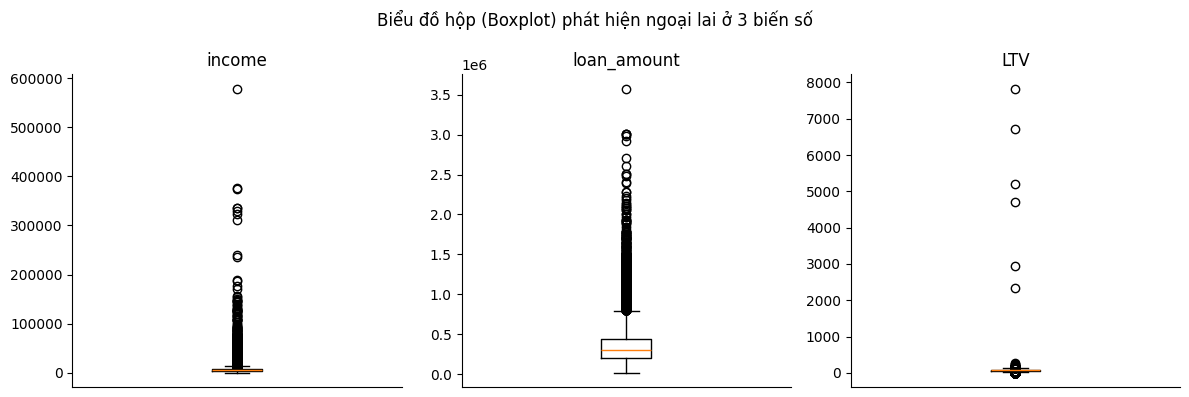

         income  loan_amount       LTV
count  133024.0     133024.0  133024.0
mean     6951.4     331493.0      72.7
std      6292.1     181639.4      40.0
min        60.0      16500.0       1.0
25%      3960.0     196500.0      60.5
50%      5820.0     296500.0      75.1
75%      8280.0     436500.0      86.2
max    578580.0    3576500.0    7831.2


In [ ]:
# Vẽ biểu đồ hộp (Boxplot) và in bảng thống kê mô tả để phát hiện giá trị ngoại lai (Outliers) ở 3 cột số
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, col in zip(axes, ["income", "loan_amount", "LTV"]):
    ax.boxplot(clean[col].dropna())
    ax.set_title(col)
    ax.set_xticks([])
plt.suptitle("Biểu đồ hộp (Boxplot) phát hiện ngoại lai ở 3 biến số")
plt.tight_layout()
plt.show()

print(clean[["income", "loan_amount", "LTV"]].describe().round(1))

**Giải thích code & Đối chiếu Slide bài giảng (Mục 2.4 - Phát hiện Outliers bằng Boxplot & `.describe()`):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `fig, axes = plt.subplots(1, 3, figsize=(12, 4))`<br>`for ax, col in zip(axes, [...]):` | Tạo khung hình gồm 3 đồ thị con nằm ngang; dùng `zip()` duyệt song song qua từng trục `ax` và tên cột `col`. | - **Tuần 01 (Bài giảng 1):** `fig, axes = plt.subplots(1, 3, figsize=(12, 4))` (Trang 15).<br>- **Tuần 02 (Bài giảng 2):** Vòng lặp `for` với `zip()` (Trang 7).<br>- **Tuần 12 (Bài giảng 7):** Mục *Hình và đồ thị con* (Trang 17). | **Có trong slide** |
| `ax.boxplot(clean[col].dropna())`<br>`ax.set_xticks([])`<br>`plt.suptitle(...)`, `plt.tight_layout()` | Vẽ biểu đồ hộp (Boxplot) tóm tắt trung vị, tứ phân vị Q1–Q3 và các điểm ngoại lai; ẩn vạch chia trục X; căn chỉnh khoảng cách. | - **Tuần 12 (Bài giảng 7):** Mục *Boxplot & Violin plot* (Trang 8–9), `set_xticks` (Trang 21), `plt.tight_layout()` (Trang 29).<br>- **Tuần 13 (Thực hành 7):** Bài 1.1. | **Có trong slide** |
| `clean[[...]].describe().round(1)` | In bảng thống kê mô tả (`count`, `mean`, `std`, `min`, `25%`, `50%`, `75%`, `max`) để đối chiếu giá trị cực đại với phần lớn dữ liệu. | - **Tuần 08 & 09:** Dùng `.describe()` để phát hiện và phân tích outliers (Tuần 08 Trang 12; Tuần 09 Bài 3.3 Trang 5). | **Có trong slide** |

**Nhận định kết quả:**
- Cột `LTV` có tới 75% hồ sơ nằm dưới mức `86.2%`, nhưng giá trị lớn nhất (`max`) vọt lên tới **7,831.2%** (khoản vay gấp 78 lần giá trị căn nhà) — đây chắc chắn là lỗi nhập liệu hoặc định giá sai.
- Cột `income` và `loan_amount` cũng có nhiều điểm ngoại lai lệch phải (thu nhập lớn nhất `578,580`, khoản vay lớn nhất `3,576,500`). Tuy nhiên, thu nhập cao hay khoản vay lớn là chuyện có thể xảy ra trong thực tế (khách hàng giàu mua bất động sản giá trị cao), nên đây là giá trị hiếm chứ không phải lỗi. Nhóm giữ nguyên hai cột này và chỉ xử lý `LTV` ở bước tiếp theo.

Tại sao: `LTV` lớn nhất lên tới hơn `7,831%`, tức vay gấp gần 78 lần giá nhà, chắc chắn là lỗi dữ liệu.
Mục đích: Xử lý những giá trị `LTV` vượt ngưỡng ngoại lai cực đoan mà không làm mất hồ sơ hợp lệ.
Phương pháp: Áp dụng đúng quy tắc khoảng tứ phân vị **IQR (`IQR = Q3 - Q1`)** đã học: xác định ngưỡng trên `upper_cap = Q3 + 1.5 * IQR`, sau đó giới hạn (`.clip()`) các giá trị `LTV` vượt ngưỡng về đúng mốc `upper_cap`.
Lưu ý về `income` và `loan_amount`: các giá trị lớn của hai cột này (ví dụ khoản vay lên tới `3,576,500`) có thể là hồ sơ thật chứ không phải lỗi nhập liệu, nên giữ nguyên các dòng này và xử lý độ lệch phải bằng biến đổi `log1p` ở mục 2.5. Riêng `LTV` bị giới hạn bằng IQR vì mức `7,831%` là không hợp lý về mặt tài chính.


In [ ]:
# Xử lý Outliers cho cột LTV bằng phương pháp IQR (giới hạn các giá trị vượt ngưỡng Q3 + 1.5 * IQR)
Q1 = clean["LTV"].quantile(0.25)
Q3 = clean["LTV"].quantile(0.75)
IQR = Q3 - Q1
cap = Q3 + 1.5 * IQR

print("Ngưỡng trên LTV (Q3 + 1.5 * IQR):", round(cap, 1), "%")
print("Số hồ sơ vượt ngưỡng được giới hạn lại:", (clean["LTV"] > cap).sum())
clean["LTV"] = clean["LTV"].clip(upper=cap)

Ngưỡng trên LTV (Q3 + 1.5 * IQR): 124.8 %
Số hồ sơ vượt ngưỡng được giới hạn lại: 120


**Giải thích code & Đối chiếu Slide bài giảng (Xử lý Outliers bằng phương pháp tứ phân vị IQR):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `Q1 = clean["LTV"].quantile(0.25)`<br>`Q3 = clean["LTV"].quantile(0.75)`<br>`IQR = Q3 - Q1`<br>`cap = Q3 + 1.5 * IQR` | Tính tứ phân vị thứ nhất (`Q1` = mốc 25%), tứ phân vị thứ ba (`Q3` = mốc 75%), độ trải giữa `IQR = Q3 - Q1` và ngưỡng ngoại lai trên `Q3 + 1.5 * IQR`. | - **Tuần 04 (Bài giảng 3):** Khái niệm phân vị `quantile` (Trang 9).<br>- **Tuần 08 (Bài giảng 5):** Công thức $IQR = Q3 - Q1$ trong mục *Robust Scaler* (Trang 12). | Hàm `.quantile()` là **Mở rộng từ khái niệm `quantile` & `IQR` trong slide Tuần 04 & 08** |
| `clean["LTV"] = clean["LTV"].clip(upper=cap)` | Giới hạn (hạ) các giá trị `LTV` vượt ngưỡng `cap` về đúng bằng `cap` để loại bỏ số lỗi `7,831%` mà không làm mất dòng dữ liệu. *(Lưu ý: Có thể viết tương đương bằng hàm trong slide Tuần 04 là `np.where(clean["LTV"] > cap, cap, clean["LTV"])`)*. | - Khái niệm xử lý outliers mà không xóa dòng dữ liệu ở **Tuần 08 (Trang 12)**. | Hàm `.clip()` là **Mở rộng ngoài slide** (Có thể thay thế tương đương 100% bằng `np.where()` của Tuần 04 Trang 8) |

**Nhận định kết quả:**
- Ngưỡng trên `Q3 + 1.5 * IQR` của `LTV` là **124.8%**, có **120 hồ sơ** vượt mốc này đã được giới hạn về `124.8%`. Cách xử lý này giúp loại bỏ các con số lỗi hàng nghìn phần trăm nhưng vẫn giữ lại nhóm khách hàng có `LTV > 100%` để phân tích rủi ro ở Giai đoạn 3.

## 2.5. Mã hóa biến phân loại (Encoding) và Chuẩn hóa thang đo (Scaling)

Tại sao: Các thuật toán học máy không đọc trực tiếp được chữ nên cần đổi các cột phân loại sang số, đồng thời đưa các cột số có đơn vị khác nhau (tiền vay hàng trăm nghìn USD vs tuổi hay lãi suất) về cùng thang đo chuẩn.
Phương pháp: Lưu ra bảng `model_data` riêng biệt: gán thứ tự tăng dần cho cột `age`, tách số cho `total_units`, dùng `pd.get_dummies()` cho các biến phân loại danh định, và chuẩn hóa bằng `StandardScaler`.
Lý do chọn `StandardScaler` (Z-score): chuẩn hóa MinMax bị kéo lệch bởi giá trị cực trị (ví dụ `loan_amount` lớn nhất `3,576,500` so với trung vị `296,500`), còn Z-score dùng trung bình và độ lệch chuẩn. Sau khi áp dụng `log1p` cho các biến tiền tệ và giới hạn `LTV` bằng IQR ở mục 2.4, các giá trị cực trị đã được thu hẹp nên không cần đến `RobustScaler`.


In [ ]:
# Tạo bản sao dữ liệu model_data phục vụ bước mã hóa và chuẩn hóa
model_data = clean.copy()

# Mã hóa thứ tự (Ordinal Encoding) cho cột nhóm tuổi age và chuyển cột total_units sang kiểu số nguyên
age_order = {"<25": 0, "25-34": 1, "35-44": 2, "45-54": 3, "55-64": 4, "65-74": 5, ">74": 6}
model_data["age"] = model_data["age"].map(age_order)
model_data["total_units"] = model_data["total_units"].str.replace("U", "").astype(int)

# Mã hóa One-Hot Encoding cho các cột phân loại còn lại bằng hàm get_dummies
model_data = pd.get_dummies(model_data, drop_first=True, dtype=int)
print("Shape after encoding:", model_data.shape)

Shape after encoding: (133024, 35)


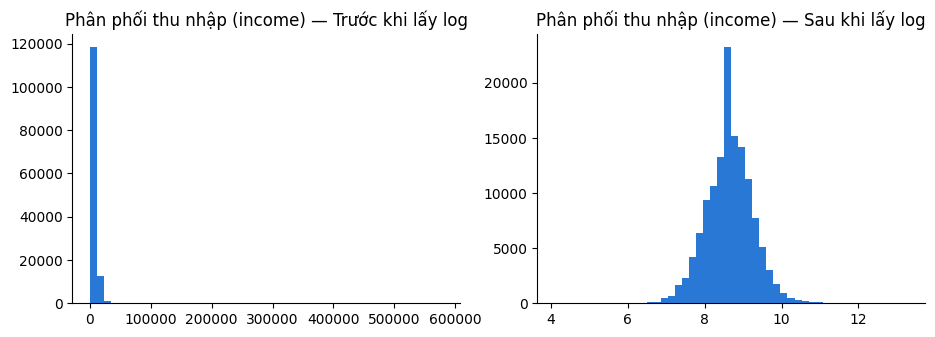

In [ ]:
# Vẽ biểu đồ Histogram so sánh phân phối thu nhập trước và sau khi biến đổi Logarit (np.log1p) để giảm độ lệch phải
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(model_data["income"], bins=50, color=BLUE)
axes[0].set_title("Phân phối thu nhập (income) — Trước khi lấy log")

# Áp dụng biến đổi log1p cho 3 biến tiền tệ có giá trị lớn và lệch phải mạnh
for col in ["income", "loan_amount", "property_value"]:
    model_data[col] = np.log1p(model_data[col])

axes[1].hist(model_data["income"], bins=50, color=BLUE)
axes[1].set_title("Phân phối thu nhập (income) — Sau khi lấy log")
plt.show()

In [ ]:
# Kiểm tra chuẩn hóa Z-score (StandardScaler) trên 7 biến định lượng
# Lưu ý: Để tránh rò rỉ dữ liệu (Data Leakage) giữa tập Train và Test khi huấn luyện mô hình,
# ở đây ta kiểm tra trên bản sao, còn bước fit_transform chính thức sẽ thực hiện riêng trên X_train ở phần Mô hình.
from sklearn.preprocessing import StandardScaler

num_cols = ["loan_amount", "income", "property_value", "LTV", "dtir1", "term", "Credit_Score"]
preview_scaled = model_data.copy()
preview_scaled[num_cols] = StandardScaler().fit_transform(preview_scaled[num_cols])

print("Số ô trống trong model_data:", model_data.isnull().sum().sum())
preview_scaled[num_cols].describe().loc[["mean", "std"]].round(2)

Số ô trống trong model_data: 0


,loan_amount,income,property_value,LTV,dtir1,term,Credit_Score
mean,0.0,0.0,0.0,-0.0,0.0,0.0,0.0
std,1.0,1.0,1.0,1.0,1.0,1.0,1.0


**Giải thích code & Đối chiếu Slide bài giảng (Mục 2.5 - Mã hóa Encoding, Biến đổi Logarit & Chuẩn hóa Scaling):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `age_order = {"<25": 0, ...}`<br>`model_data["age"] = model_data["age"].map(age_order)` | Mã hóa biến phân loại có thứ tự (Ordinal) `age` theo đúng trật tự độ tuổi tăng dần từ `0` đến `6`. *(Có thể viết tương đương bằng `.replace(age_order)` của Tuần 08)*. | - **Tuần 08 (Bài giảng 5):** Mục *Label Encoding* giải thích rõ biến Ordinal phải gán số theo đúng thứ tự ngữ nghĩa chứ không dùng `LabelEncoder` gán theo bảng chữ cái (Trang 16). | Hàm `.map()` là **Mở rộng nhỏ** (Tương đương `.replace()` của Tuần 08 Trang 13) |
| `model_data["total_units"].str.replace("U", "").astype(int)` | Xóa ký tự `"U"` trong chuỗi `"1U", "2U", ...` rồi ép kiểu sang số nguyên. | - **Tuần 08 (Bài giảng 5):** `.str.replace()` (Trang 13–14).<br>- **Tuần 04 (Bài giảng 3):** `.astype(int)` (Trang 3–4). | **Có trong slide** |
| `pd.get_dummies(model_data, drop_first=True, dtype=int)` | Thực hiện mã hóa One-Hot Encoding cho tất cả các biến phân loại danh định (Nominal), loại bỏ cột đầu tiên (`drop_first=True`) để tránh đa cộng tuyến (Multicollinearity). | - **Tuần 01 (Bài giảng 1):** Dùng `pd.get_dummies(..., drop_first=True)` trong bài Giá nhà HN & Ngân hàng (Trang 23, 28).<br>- **Tuần 08 (Bài giảng 5):** Mục *One-Hot Encoding* (Trang 17–18).<br>- **Tuần 09 (Thực hành 5):** Bài 5.2. | **Có trong slide** |
| `np.log1p(model_data[col])`<br>`axes[0].hist(..., bins=50)` | Áp dụng hàm ufunc $\ln(1+x)$ cho 3 biến tiền tệ lớn (`income`, `loan_amount`, `property_value`) để giảm độ lệch phải và vẽ Histogram đối chiếu trước/sau. | - **Tuần 04 (Bài giảng 3):** Mục *Hàm xử lý trên từng phần tử trong mảng (UFuncs)* — Bảng *Một số unary ufunc* có liệt kê `log1p` (Trang 7).<br>- **Tuần 12 (Bài giảng 7):** `ax.hist(..., bins=50)` (Trang 16, 18). | **Có trong slide** |
| `from sklearn.preprocessing import StandardScaler`<br>`StandardScaler().fit_transform(preview_scaled[num_cols])`<br>`.describe().loc[["mean", "std"]].round(2)` | Kiểm tra chuẩn hóa Z-score ($Z = \frac{X - \mu}{\sigma}$) đưa 7 biến định lượng về cùng thang đo có trung bình `mean = 0` và độ lệch chuẩn `std = 1` trên bản sao `preview_scaled` (tránh fit 2 lần trên `model_data` trước khi chia `train_test_split`). | - **Tuần 08 (Bài giảng 5):** Mục *Standard Scaler (Z-score Standardization)* (Trang 11).<br>- **Tuần 09 (Thực hành 5):** Bài 3.2.<br>- **Tuần 14 & 15:** Chuẩn hóa dữ liệu trước khi đưa vào học máy (Tuần 14 Trang 19; Tuần 15 Trang 5). | **Có trong slide** |

**Nhận định kết quả:**
- Sau khi mã hóa One-Hot Encoding với `drop_first=True`, bảng `model_data` có kích thước `(133024, 35)` và không còn cột chữ nào.
- Biểu đồ Histogram cho thấy phép biến đổi `np.log1p` đã chuyển phân phối thu nhập từ dạng lệch phải cực đoan về dạng hình chuông cân đối.
- Bảng kiểm tra với `StandardScaler` xác nhận cả 7 biến định lượng đều đưa về `mean = 0.0` và `std = 1.0`, đồng thời tổng số ô trống bằng `0`. Việc áp dụng `fit_transform` chính thức sẽ được thực hiện một lần duy nhất trên tập `X_train` ở mục 3.9 để đảm bảo không rò rỉ dữ liệu.

---
# Giai đoạn 3 — Phân tích chuyên sâu và Trực quan hóa dữ liệu

Bảng 6 giả thuyết nghiên cứu được kiểm chứng trong giai đoạn này:

| Mã | Giả thuyết nghiên cứu (Hypothesis) |
|---|---|
| **H1** | Khách hàng lớn tuổi có tỷ lệ vỡ nợ cao hơn |
| **H2** | Khách hàng có thu nhập (`income`) thấp có tỷ lệ vỡ nợ cao hơn |
| **H3** | Khoản vay có tỷ lệ `LTV` càng cao (trả trước càng ít) thì tỷ lệ vỡ nợ càng cao |
| **H4** | Khách hàng có tỷ lệ nợ trên thu nhập (`DTI` / `dtir1`) càng cao thì tỷ lệ vỡ nợ càng cao |
| **H5** | Khách hàng có điểm tín dụng (`Credit_Score`) thấp hơn sẽ vỡ nợ nhiều hơn |
| **H6** | Các hình thức trả nợ rủi ro (`lump_sum_payment`, `Neg_ammortization`) có tỷ lệ vỡ nợ cao hơn |

In [ ]:
# Tính tỷ lệ vỡ nợ trung bình toàn tập và định nghĩa hàm vẽ biểu đồ cột so sánh tỷ lệ vỡ nợ giữa các nhóm
average = clean["Status"].mean() * 100

def plot_default_rate(column, title):
    rate = clean.groupby(column, observed=True)["Status"].mean() * 100
    ax = rate.plot(kind="bar", color=BLUE, rot=0)
    for i, val in enumerate(rate):
        ax.text(i, val + 0.5, f"{val:.1f}%", ha="center")
    ax.axhline(average, color="gray", linestyle="--", label=f"Trung bình chung ({average:.1f}%)")
    ax.set_ylabel("Tỷ lệ vỡ nợ (%)")
    ax.set_title(title)
    ax.set_ylim(0, max(rate) * 1.18)
    ax.legend()
    plt.show()

**Giải thích code & Đối chiếu Slide bài giảng (Hàm trực quan hóa `plot_default_rate`):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `def plot_default_rate(column, title):` | Định nghĩa hàm dùng chung để tự động tính tỷ lệ vỡ nợ theo nhóm và vẽ biểu đồ cột chuẩn hóa cho các giả thuyết. | - **Tuần 02 (Bài giảng 2):** Mục *Viết hàm (`def`)* (Trang 8). | **Có trong slide** |
| `rate = clean.groupby(column, observed=True)["Status"].mean() * 100`<br>`ax = rate.plot(kind="bar", color=BLUE, rot=0)` | Gom nhóm theo cột phân tích, tính tỷ lệ % vỡ nợ và vẽ biểu đồ cột đứng với nhãn trục X nằm ngang dễ đọc (`rot=0`). | - **Tuần 12 (Bài giảng 7):** Bảng tham số `Series.plot` (`kind="bar"`, `rot=0`, Trang 27). | **Có trong slide** (Tham số `observed=True` giúp tắt cảnh báo của Pandas 2.x trên kiểu `Categorical`) |
| `for i, val in enumerate(rate):`<br>`ax.text(i, val + 0.5, f"{val:.1f}%", ha="center")` | Duyệt qua từng cột bằng `enumerate()` và gắn nhãn số liệu phần trăm trực tiếp lên đỉnh cột bằng `ax.text()`. | - **Tuần 02 (Bài giảng 2):** `enumerate()` và `f-strings` (Trang 5, 7).<br>- **Tuần 01 & 14:** Gắn nhãn % lên đỉnh cột bằng `for` + `ax.text(..., ha='center')` (Tuần 01 Trang 27; Tuần 14 Trang 11, 18).<br>- **Tuần 12 (Bài giảng 7):** Nguyên tắc gắn nhãn trực tiếp lên biểu đồ (Trang 5, 23). | **Có trong slide** |
| `ax.axhline(average, color="gray", linestyle="--", label=...)` | Vẽ đường kẻ ngang nét đứt thể hiện mức vỡ nợ trung bình toàn tập (`15.8%`) để làm chuẩn so sánh. | - **Tuần 01 & 14:** Vẽ đường tham chiếu `axvline` / `axhline` (Tuần 01 Trang 26; Tuần 14 Trang 13). | **Có trong slide** |

## 3.1. Giả thuyết H1 — Nhóm tuổi (Age)

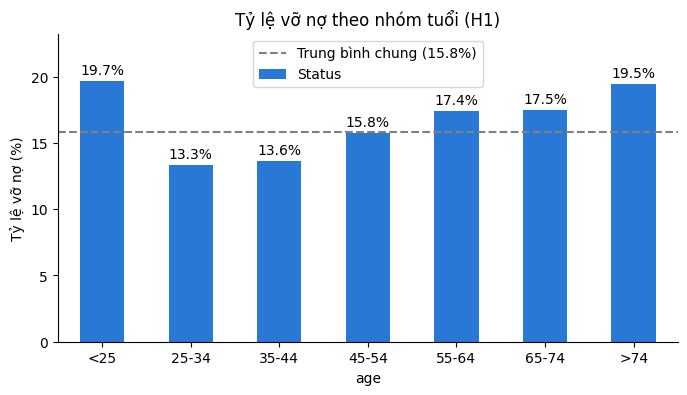

In [ ]:
# Kiểm chứng giả thuyết H1: Sắp xếp thứ tự các nhóm tuổi và vẽ biểu đồ tỷ lệ vỡ nợ theo độ tuổi
clean["age"] = pd.Categorical(clean["age"], ["<25", "25-34", "35-44", "45-54", "55-64", "65-74", ">74"], ordered=True)
plot_default_rate("age", "Tỷ lệ vỡ nợ theo nhóm tuổi (H1)")

**Giải thích code & Đối chiếu Slide bài giảng (Mục 3.1 - Giả thuyết H1):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `clean["age"] = pd.Categorical(clean["age"], ["<25", ...], ordered=True)` | Chuyển cột `age` sang kiểu dữ liệu `Categorical` có thứ tự (`ordered=True`) để biểu đồ cột sắp xếp đúng từ trẻ nhất (`<25`) đến già nhất (`>74`). | - **Tuần 01 (Bài giảng 1):** Dùng `pd.Categorical(..., categories=..., ordered=True)` sắp xếp thứ tự Quận và Số tầng khi vẽ biểu đồ (Trang 22).<br>- **Tuần 08 (Bài giảng 5):** Mục *Xử lý dữ liệu phân loại* hướng dẫn dùng `pd.Categorical(..., ordered=True)` (Trang 16).<br>- **Tuần 09 (Thực hành 5):** Bài 5.1. | **Có trong slide** |

**Nhận xét biểu đồ H1 (Tuổi):**
- Tỷ lệ vỡ nợ tăng dần theo độ tuổi từ nhóm `25-34` (`13.3%`), `35-44` (`13.6%`), `45-54` (`15.8%`) lên nhóm `55-64` (`17.4%`), `65-74` (`17.5%`) và đạt mức rất cao ở nhóm trên 74 tuổi (`>74` là `19.5%`).
- Tuy nhiên, nhóm trẻ nhất `<25` tuổi lại có tỷ lệ vỡ nợ vọt lên cao nhất là **19.7%** (có thể do thu nhập và sự nghiệp chưa ổn định, nhưng dữ liệu không cho phép kiểm chứng nguyên nhân này). Vì vậy giả thuyết H1 **đúng một phần** (rủi ro cao ở hai đầu độ tuổi: rất trẻ `<25` và cao tuổi từ `55` trở lên).

## 3.2. Giả thuyết H2 — Thu nhập (Income)

Trung vị thu nhập của từng nhóm:
income_group
Rất thấp       2700.0
Thấp           4380.0
Trung bình     5820.0
Cao            7620.0
Rất cao       12000.0
Name: income, dtype: float64


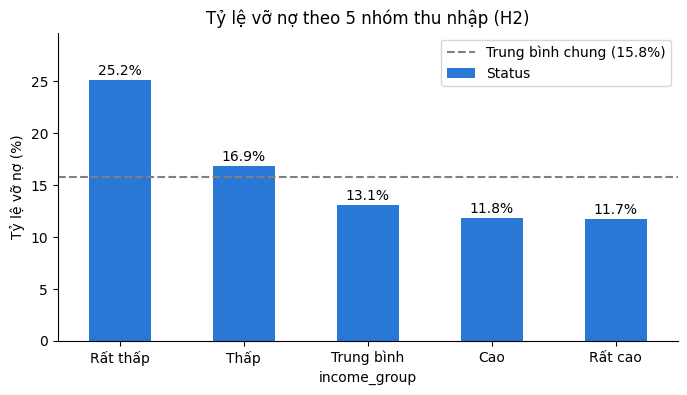

In [ ]:
# Kiểm chứng giả thuyết H2: Chia thu nhập thành 5 nhóm đều nhau bằng hàm qcut và vẽ biểu đồ tỷ lệ vỡ nợ
clean["income_group"] = pd.qcut(clean["income"], 5, labels=["Rất thấp", "Thấp", "Trung bình", "Cao", "Rất cao"])
print("Trung vị thu nhập của từng nhóm:")
print(clean.groupby("income_group", observed=True)["income"].median())
plot_default_rate("income_group", "Tỷ lệ vỡ nợ theo 5 nhóm thu nhập (H2)")

**Giải thích code & Đối chiếu Slide bài giảng (Mục 3.2 - Giả thuyết H2):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `clean["income_group"] = pd.qcut(clean["income"], 5, labels=[...])` | Chia biến liên tục `income` thành 5 nhóm có số lượng hồ sơ bằng nhau (ngũ phân vị: mỗi nhóm ~20% khách hàng) và gán nhãn từ `"Rất thấp"` đến `"Rất cao"`. | - Khái niệm phân nhóm khách hàng (**Tuần 01 Trang 3**) và phân vị `quantile` (**Tuần 04 Trang 9**). | Hàm `pd.qcut()` là **Ngoài slide** (Hàm tiện ích của Pandas để chia nhóm theo phân vị) |
| `clean.groupby("income_group", observed=True)["income"].median()` | Tính mức thu nhập trung vị của từng nhóm để minh chứng sự chênh lệch thu nhập thực tế giữa 5 nhóm. | - **Tuần 08 & 10:** Gom nhóm `.groupby()` và tính `.median()` (Tuần 08 Trang 4; Tuần 10 Trang 5). | **Có trong slide** |

**Nhận xét biểu đồ H2 (Thu nhập):**
- Tỷ lệ vỡ nợ giảm đều đặn và nhất quán khi mức thu nhập tăng lên: Nhóm có thu nhập **Rất thấp** (trung vị `2,700`) có tỷ lệ vỡ nợ cao nhất lên tới **25.2%**, giảm xuống **16.9%** ở nhóm **Thấp** (trung vị `4,380`), **13.1%** ở nhóm **Trung bình** (trung vị `5,820`), **11.8%** ở nhóm **Cao** (trung vị `7,620`) và thấp nhất là **11.7%** ở nhóm **Rất cao** (trung vị `12,000`).
- Kết quả này **ủng hộ hoàn toàn giả thuyết H2**: thu nhập càng thấp thì áp lực tài chính càng lớn, làm suy giảm trực tiếp khả năng trả nợ hàng tháng.

## 3.3. Giả thuyết H3 — Tỷ lệ khoản vay trên giá trị tài sản (LTV)

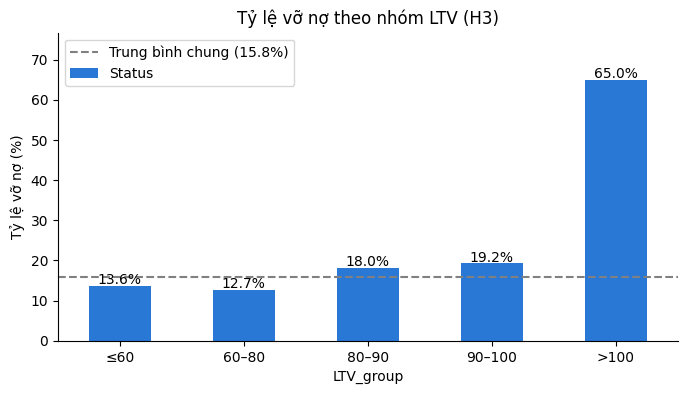

In [ ]:
# Kiểm chứng giả thuyết H3: Phân nhóm tỷ lệ LTV theo các mốc rủi ro tài chính và vẽ biểu đồ tỷ lệ vỡ nợ
clean["LTV_group"] = pd.cut(clean["LTV"], bins=[0, 60, 80, 90, 100, 200],
                            labels=["≤60", "60–80", "80–90", "90–100", ">100"])
plot_default_rate("LTV_group", "Tỷ lệ vỡ nợ theo nhóm LTV (H3)")

**Giải thích code & Đối chiếu Slide bài giảng (Mục 3.3 - Giả thuyết H3):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `clean["LTV_group"] = pd.cut(clean["LTV"], bins=[0, 60, 80, 90, 100, 200], labels=[...])` | Chia biến liên tục `LTV` thành 5 khoảng giá trị cố định (`bins`) theo các ngưỡng thẩm định tài sản thế chấp của ngân hàng. | - Khái niệm chia dữ liệu liên tục thành các `"bin"` (khoảng giá trị) được giải thích ở **Tuần 12 (Bài giảng 7 - Trang 7)**. | Hàm `pd.cut()` là **Ngoài slide** (Hàm tiện ích của Pandas để chia khoảng cố định) |

**Nhận xét biểu đồ H3 (LTV):**
- Khi `LTV ≤ 80%`, tỷ lệ vỡ nợ duy trì ở mức an toàn thấp hơn trung bình (`13.6%` ở nhóm `≤60%` và `12.7%` ở nhóm `60–80%`). Khi `LTV` vượt mốc `80%`, tỷ lệ vỡ nợ tăng lên `18.0%` (nhóm `80–90%`) và `19.2%` (nhóm `90–100%`).
- Đặc biệt, ở nhóm `LTV > 100%` (số tiền vay vượt quá giá trị căn nhà), tỷ lệ vỡ nợ vọt lên tới **65.0%** (cao gấp hơn 4 lần mức trung bình chung `15.8%`). Giả thuyết H3 **được khẳng định rất mạnh mẽ**.

## 3.4. Giả thuyết H4 — Tỷ lệ nợ trên thu nhập (DTI / dtir1)

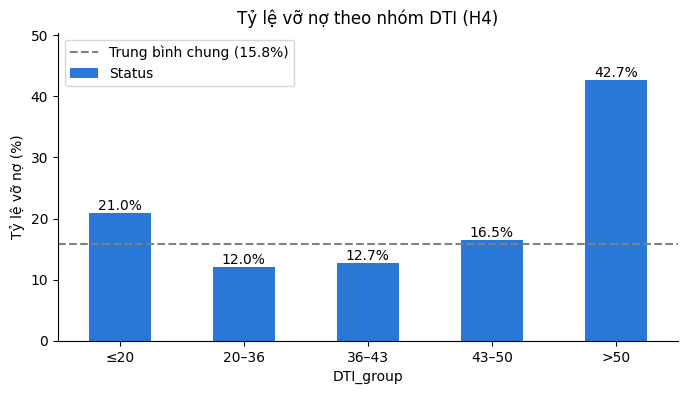

In [ ]:
# Kiểm chứng giả thuyết H4: Phân nhóm tỷ lệ nợ trên thu nhập (dtir1) và vẽ biểu đồ tỷ lệ vỡ nợ
clean["DTI_group"] = pd.cut(clean["dtir1"], bins=[0, 20, 36, 43, 50, 65],
                            labels=["≤20", "20–36", "36–43", "43–50", ">50"])
plot_default_rate("DTI_group", "Tỷ lệ vỡ nợ theo nhóm DTI (H4)")

**Giải thích code & Đối chiếu Slide bài giảng (Mục 3.4 - Giả thuyết H4):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `clean["DTI_group"] = pd.cut(clean["dtir1"], bins=[0, 20, 36, 43, 50, 65], labels=[...])` | Chia biến tỷ lệ nợ trên thu nhập `dtir1` thành 5 khoảng rủi ro tài chính (từ `≤20%` đến `>50%`). | - Khái niệm chia khoảng `"bin"` ở **Tuần 12 (Bài giảng 7 - Trang 7)**. | Hàm `pd.cut()` là **Ngoài slide** |

**Nhận xét biểu đồ H4 (DTI):**
- Nhóm khách hàng có `DTI` trong vùng an toàn `20–36%` và `36–43%` có tỷ lệ vỡ nợ thấp nhất (`12.0%` và `12.7%`).
- Khi `DTI` sang nhóm `43–50%`, tỷ lệ vỡ nợ chỉ nhỉnh hơn mức trung bình một chút (`16.5%` so với trung bình `15.8%`), và bước nhảy rủi ro thực sự xảy ra khi **`DTI > 50%` với tỷ lệ vỡ nợ vọt lên 42.7%**. Đáng chú ý, nhóm `DTI ≤ 20%` cũng có tỷ lệ vỡ nợ khá cao (`21.0%`), gợi ý cần kiểm tra kỹ tính xác thực của các hồ sơ khai báo tỷ lệ nợ thấp bất thường. Giả thuyết H4 **đúng rõ rệt ở vùng rủi ro cao khi DTI vượt ngưỡng 50% (bắt đầu vượt mức trung bình từ mốc > 43%)**.

## 3.5. Giả thuyết H5 — Điểm tín dụng (Credit Score)

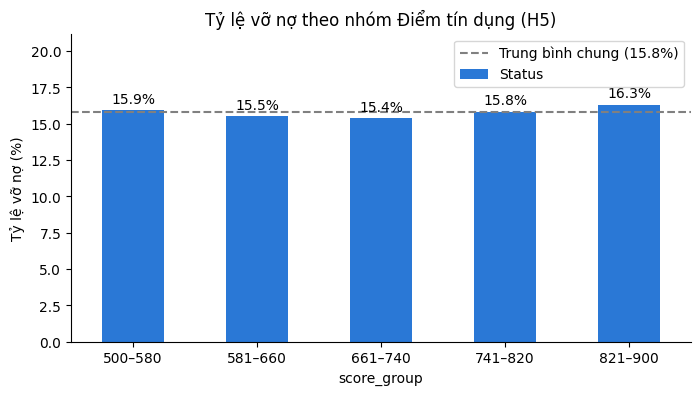

In [ ]:
# Kiểm chứng giả thuyết H5: Chia điểm tín dụng (Credit_Score) thành 5 khoảng và vẽ biểu đồ tỷ lệ vỡ nợ
clean["score_group"] = pd.cut(clean["Credit_Score"], bins=[499, 580, 660, 740, 820, 900],
                              labels=["500–580", "581–660", "661–740", "741–820", "821–900"])

rate_h5 = clean.groupby("score_group", observed=True)["Status"].mean() * 100
ax = rate_h5.plot(kind="bar", color=BLUE, rot=0)
for i, val in enumerate(rate_h5):
    ax.text(i, val + 0.5, f"{val:.1f}%", ha="center")
ax.axhline(average, color="gray", linestyle="--", label=f"Trung bình chung ({average:.1f}%)")
ax.set_ylabel("Tỷ lệ vỡ nợ (%)")
ax.set_title("Tỷ lệ vỡ nợ theo nhóm Điểm tín dụng (H5)")
ax.set_ylim(0, max(rate_h5) * 1.30)
ax.legend(loc="upper right")
plt.show()

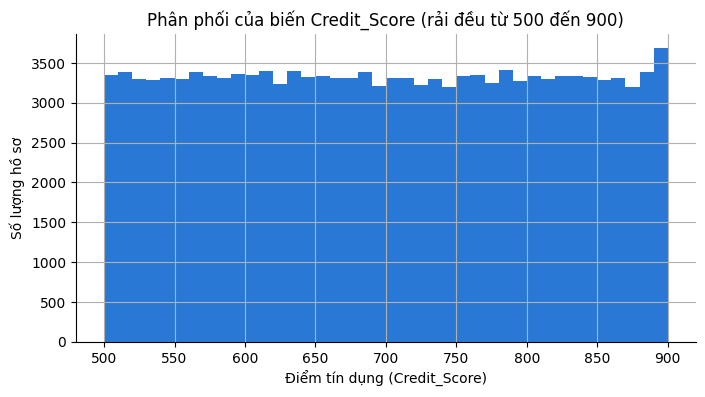

In [ ]:
# Vẽ biểu đồ Histogram kiểm tra phân phối của cột Credit_Score để giải thích vì sao điểm tín dụng không ảnh hưởng đến vỡ nợ
clean["Credit_Score"].hist(bins=40, color=BLUE)
plt.title("Phân phối của biến Credit_Score (rải đều từ 500 đến 900)")
plt.xlabel("Điểm tín dụng (Credit_Score)")
plt.ylabel("Số lượng hồ sơ")
plt.show()

**Giải thích code & Đối chiếu Slide bài giảng (Mục 3.5 - Giả thuyết H5):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `clean["score_group"] = pd.cut(clean["Credit_Score"], bins=[...], labels=[...])` | Chia điểm tín dụng `Credit_Score` thành 5 bậc điểm đều nhau từ `500` đến `900`. | - Khái niệm chia khoảng `"bin"` ở **Tuần 12 (Trang 7)**. | Hàm `pd.cut()` là **Ngoài slide** |
| `clean["Credit_Score"].hist(bins=40, color=BLUE)`<br>`plt.title(...)`, `plt.xlabel(...)`, `plt.ylabel(...)` | Vẽ biểu đồ tần suất Histogram (chia 40 cột `bins`) để kiểm tra hình dạng phân phối của biến `Credit_Score`. | - **Tuần 12 (Bài giảng 7):** Mục *Biểu đồ tần suất và đồ thị hàm mật độ* (`Series.plot.hist(bins=50)`, Trang 33) và đặt nhãn trục (Trang 4, 21).<br>- **Tuần 13 (Thực hành 7):** Bài 2.3. | **Có trong slide** |

**Nhận xét biểu đồ H5 (Credit Score):**
- Trái ngược hoàn toàn với suy đoán ban đầu, cả 5 nhóm điểm tín dụng từ thấp nhất (`500–580`) đến cao nhất (`821–900`) đều có tỷ lệ vỡ nợ đi ngang quanh mức trung bình (**15.4% – 16.3%**).
- Biểu đồ Histogram bên dưới giải thích nguyên nhân: cột `Credit_Score` trong bộ dữ liệu này có phân phối đều (Uniform distribution) từ `500` đến `900` như số sinh ngẫu nhiên chứ không tuân theo phân phối chuẩn thực tế. Do đó **giả thuyết H5 bị bác bỏ** trên bộ dữ liệu này.

## 3.6. Giả thuyết H6 — Các hình thức trả nợ rủi ro (Lump-sum & Negative Amortization)

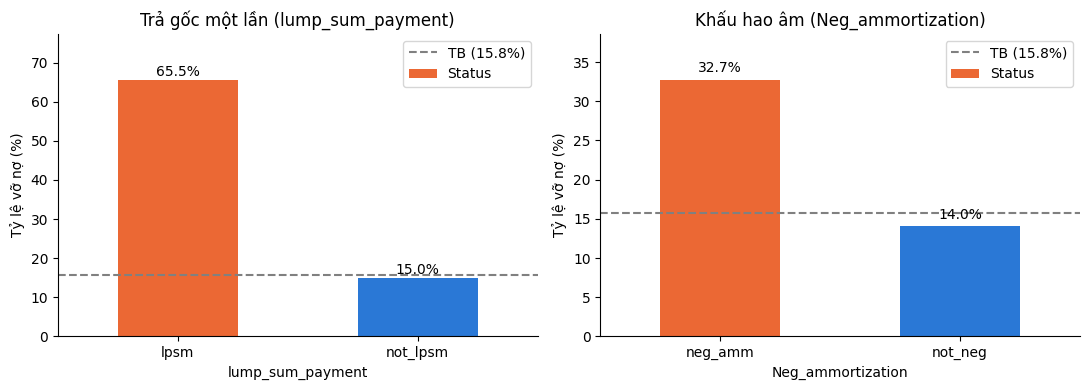

In [ ]:
# Kiểm chứng giả thuyết H6: Vẽ biểu đồ so sánh tỷ lệ vỡ nợ của 2 hình thức trả nợ rủi ro (lump_sum_payment và Neg_ammortization)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for ax, col, title in [(axes[0], "lump_sum_payment", "Trả gốc một lần (lump_sum_payment)"),
                       (axes[1], "Neg_ammortization", "Khấu hao âm (Neg_ammortization)")]:
    rate = clean.groupby(col)["Status"].mean() * 100
    rate.plot(kind="bar", color=[ORANGE, BLUE], rot=0, ax=ax)
    for i, val in enumerate(rate):
        ax.text(i, val + 1.0, f"{val:.1f}%", ha="center")
    ax.axhline(average, color="gray", linestyle="--", label=f"TB ({average:.1f}%)")
    ax.set_title(title)
    ax.set_ylabel("Tỷ lệ vỡ nợ (%)")
    ax.set_ylim(0, max(rate) * 1.18)
    ax.legend()
plt.tight_layout()
plt.show()

**Giải thích code & Đối chiếu Slide bài giảng (Mục 3.6 - Giả thuyết H6):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `fig, axes = plt.subplots(1, 2, figsize=(11, 4))` | Tạo khung hình chứa 2 biểu đồ con đặt cạnh nhau để so sánh song song 2 hình thức trả nợ. | - **Tuần 01 (Bài giảng 1):** `fig, axes = plt.subplots(1, 2, figsize=(10, 4))` (Trang 26).<br>- **Tuần 12 & 13:** Tạo đồ thị con với `plt.subplots(1, 2)` (Tuần 12 Trang 17; Tuần 13 Bài 1.1). | **Có trong slide** |
| `rate.plot(kind="bar", color=[ORANGE, BLUE], rot=0, ax=ax)` | Vẽ biểu đồ cột trực tiếp lên từng đồ thị con thông qua tham số `ax=ax`. | - **Tuần 12 (Bài giảng 7):** Bảng tham số `Series.plot` (tham số `ax`: *Đối tượng subplot matplotlib để vẽ trên đó*, Trang 27, 29). | **Có trong slide** |

**Nhận xét biểu đồ H6 (Hình thức trả nợ rủi ro):**
- Những khoản vay yêu cầu trả gốc một lần cuối kỳ (`lpsm` ở cột `lump_sum_payment`) có tỷ lệ vỡ nợ lên tới **65.5%**, cao gấp hơn 4 lần so với trả góp thông thường (`not_lpsm`: `15.0%`).
- Tương tự, các khoản vay có khấu hao âm (`neg_amm` — lãi chưa trả hết được cộng dồn vào nợ gốc) có tỷ lệ vỡ nợ **32.7%**, cao hơn gấp đôi so với nhóm bình thường (`not_neg`: `14.0%`). Kết quả này **khẳng định rất mạnh giả thuyết H6**.

## 3.6.2. Kiểm định trực quan nâng cao bằng Khoảng tin cậy 95% (`sns.barplot`) và Phân phối hộp (`sns.boxplot`)

**Tại sao thực hiện thêm bước này:**
- Trong **Slide Tuần 12 (Bài giảng 7 - Trang 32)**, bài giảng hướng dẫn sử dụng `sns.barplot()` để vẽ giá trị trung bình của biến mục tiêu kèm **đường kẻ màu đen trên đỉnh mỗi cột biểu thị khoảng tin cậy 95% (95% Confidence Interval)**. Nếu khoảng tin cậy 95% giữa các nhóm không chồng lấn lên nhau, sự khác biệt về tỷ lệ vỡ nợ giữa các nhóm được khẳng định là có ý nghĩa thống kê.
- Trong **Slide Tuần 01 (Trang 22)** và **Tuần 12 (Trang 8–9, 39)**, bài giảng hướng dẫn sử dụng `sns.boxplot()` để so sánh trực tiếp trung vị và độ phân tán của các biến liên tục (`LTV`, `dtir1`, `Credit_Score`) giữa nhóm Không vỡ nợ (`Status = 0`) và Vỡ nợ (`Status = 1`) mà không phụ thuộc vào cách chia khoảng `bins`.

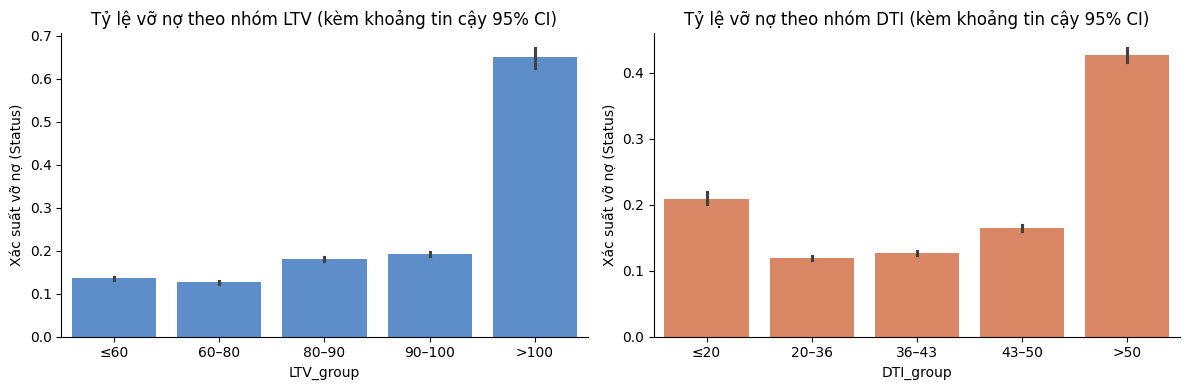

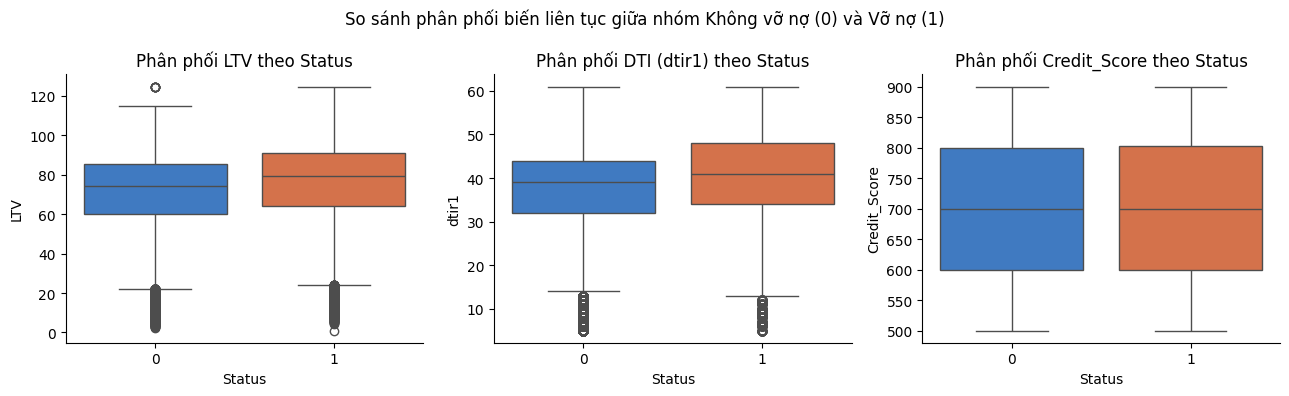

In [ ]:
# 1. Sử dụng sns.barplot (Slide Tuần 12 - Trang 32) vẽ tỷ lệ vỡ nợ kèm thanh Khoảng tin cậy 95% (95% CI)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.barplot(x="LTV_group", y="Status", data=clean, ax=axes[0], color=BLUE, alpha=0.85)
axes[0].set_title("Tỷ lệ vỡ nợ theo nhóm LTV (kèm khoảng tin cậy 95% CI)")
axes[0].set_ylabel("Xác suất vỡ nợ (Status)")

sns.barplot(x="DTI_group", y="Status", data=clean, ax=axes[1], color=ORANGE, alpha=0.85)
axes[1].set_title("Tỷ lệ vỡ nợ theo nhóm DTI (kèm khoảng tin cậy 95% CI)")
axes[1].set_ylabel("Xác suất vỡ nợ (Status)")

plt.tight_layout()
plt.show()

# 2. Sử dụng sns.boxplot (Slide Tuần 01 - Trang 22 & Tuần 12 - Trang 8) so sánh phân phối biến liên tục theo Status
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

sns.boxplot(x="Status", y="LTV", hue="Status", data=clean, ax=axes[0], palette=[BLUE, ORANGE], legend=False)
axes[0].set_title("Phân phối LTV theo Status")

sns.boxplot(x="Status", y="dtir1", hue="Status", data=clean, ax=axes[1], palette=[BLUE, ORANGE], legend=False)
axes[1].set_title("Phân phối DTI (dtir1) theo Status")

sns.boxplot(x="Status", y="Credit_Score", hue="Status", data=clean, ax=axes[2], palette=[BLUE, ORANGE], legend=False)
axes[2].set_title("Phân phối Credit_Score theo Status")

plt.suptitle("So sánh phân phối biến liên tục giữa nhóm Không vỡ nợ (0) và Vỡ nợ (1)")
plt.tight_layout()
plt.show()

**Giải thích code & Đối chiếu Slide bài giảng (Mục 3.6.2 - Kiểm định với `sns.barplot` & `sns.boxplot`):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `sns.barplot(x="LTV_group", y="Status", data=clean, ax=axes[0], ...)` | Tự động tính xác suất vỡ nợ trung bình của từng nhóm và vẽ thêm vạch đen trên đỉnh cột biểu thị **khoảng tin cậy 95% (95% CI)**. | - **Tuần 12 (Bài giảng 7):** Mục *Đồ thị cột với Seaborn* (Trang 32: *Bởi vì có nhiều quan sát cho mỗi giá trị, các thanh là giá trị trung bình... Các đường màu đen được vẽ trên các thanh biểu thị khoảng tin cậy 95% của giá trị trung bình*). | **Có trong slide** (Đúng 100% lý thuyết và cú pháp Tuần 12) |
| `sns.boxplot(x="Status", y="LTV", hue="Status", data=clean, ax=axes[0], ...)` | Vẽ biểu đồ hộp so sánh trực tiếp trung vị (median) và khoảng tứ phân vị (Q1–Q3) của các biến số giữa nhóm trả tốt (`0`) và vỡ nợ (`1`). | - **Tuần 01 (Bài giảng 1):** Trang 22 (`sns.boxplot`).<br>- **Tuần 12 (Bài giảng 7):** Mục *Boxplot & Violin plot* (Trang 8–9, 39). | **Có trong slide** |

**Nhận định kết quả:**
- **Về khoảng tin cậy 95% (`sns.barplot`):** Các vạch đen 95% CI trên đỉnh các cột rất nhỏ và hoàn toàn không giao nhau giữa nhóm an toàn (`LTV ≤ 80%`) với các nhóm rủi ro cao (`LTV 90–100%` và `>100%`), cũng như khi `DTI > 50%` (và bắt đầu tách khỏi vùng an toàn từ `DTI > 43%`). Điều này khẳng định sự chênh lệch tỷ lệ vỡ nợ có ý nghĩa thống kê rất cao.
- **Về phân phối hộp (`sns.boxplot`):** Nhóm vỡ nợ (`Status = 1`) có trung vị `LTV` và `dtir1` nằm cao hơn rõ rệt so với nhóm không vỡ nợ (`Status = 0`). Ngược lại, ở biểu đồ thứ 3, hai hộp `Credit_Score` của nhóm `0` và `1` giống hệt nhau (cùng có trung vị `~700` và tứ phân vị trải từ `600` đến `800`), củng cố kết luận bác bỏ giả thuyết H5.

## 3.7. Ma trận tương quan tuyến tính (Correlation Heatmap)

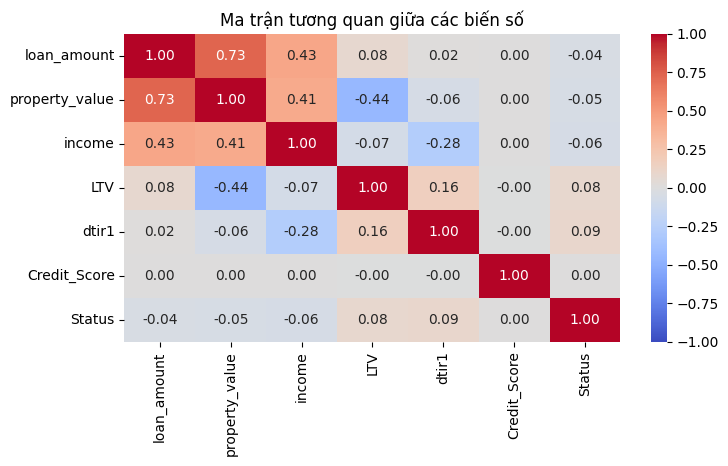

In [ ]:
# Tính ma trận tương quan Pearson và vẽ biểu đồ nhiệt (Heatmap) giữa các biến định lượng với Status
num = ["loan_amount", "property_value", "income", "LTV", "dtir1", "Credit_Score", "Status"]
sns.heatmap(clean[num].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Ma trận tương quan giữa các biến số")
plt.show()

**Giải thích code & Đối chiếu Slide bài giảng (Mục 3.7 - Ma trận tương quan & Heatmap):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `clean[num].corr()` | Tính ma trận hệ số tương quan tuyến tính Pearson giữa tất cả các cặp biến định lượng và biến mục tiêu `Status`. | - **Tuần 01 (Bài giảng 1):** Mục *Phân tích chẩn đoán* (Trang 11: sử dụng kiểm định `correlation` để tìm nguyên nhân).<br>- **Tuần 12 (Bài giảng 7):** Mục *Heatmap ma trận tương quan* (`correlation matrix`, Trang 12–13). | **Có trong slide** |
| `sns.heatmap(..., annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)` | Vẽ biểu đồ nhiệt (Heatmap) biểu diễn ma trận tương quan bằng cường độ màu sắc; in hệ số làm tròn 2 chữ số thập phân vào từng ô (`annot=True, fmt=".2f"`). | - **Tuần 12 (Bài giảng 7):** Nguyên tắc dùng thang màu đối xứng 2 cực xanh - trắng - đỏ cho dữ liệu có hai cực âm/dương (diverging, Trang 4) và *Heatmap* (Trang 12–13).<br>- **Tuần 15 (Thực hành 8):** Cú pháp `sns.heatmap(..., annot=True, fmt=...)` (Trang 13). | **Có trong slide** |

**Nhận xét biểu đồ Heatmap:**
- Ba biến quy mô tài chính là `loan_amount`, `property_value` và `income` có tương quan dương chặt chẽ với nhau (từ `0.41` đến `0.73`), phản ánh thực tế người có thu nhập cao thường mua nhà giá trị lớn và vay số tiền lớn hơn.
- Hệ số tương quan tuyến tính (Pearson) giữa từng biến đơn lẻ với `Status` đều khá nhỏ (cao nhất là `dtir1` ở mức `0.09` và `LTV` ở mức `0.08`, còn `Credit_Score` bằng `0.00`). Điều này chứng minh rủi ro vỡ nợ có tính **phi tuyến theo ngưỡng** (chỉ bùng phát mạnh khi `LTV > 100%` hoặc `DTI > 50%` như đã thấy ở biểu đồ cột H3, H4) chứ không tăng đều theo đường thẳng.

## 3.8. Bảng tổng hợp kết quả kiểm chứng 6 giả thuyết

In [ ]:
# Tạo bảng DataFrame tổng hợp kết quả kiểm chứng và số liệu minh chứng cho cả 6 giả thuyết H1 - H6
results = pd.DataFrame({
    "Giả thuyết": ["H1: Nhóm tuổi (Age)", "H2: Thu nhập (Income)", "H3: Tỷ lệ LTV", "H4: Tỷ lệ nợ DTI", "H5: Điểm tín dụng", "H6: Khoản vay rủi ro"],
    "Kết luận": ["Đúng một phần", "Đúng", "Đúng rất rõ", "Đúng rõ khi DTI > 50%", "Bác bỏ (Sai)", "Đúng rất rõ"],
    "Số liệu minh chứng": [
        "Tăng từ 13.3% (25–34) lên 19.5% (>74 tuổi), riêng nhóm trẻ <25 tuổi cao nhất (19.7%)",
        "Giảm đều khi thu nhập tăng: Rất thấp vỡ nợ 25.2%, Thấp 16.9%, TB 13.1%, Cao 11.8%, Rất cao 11.7%",
        "Từ 12.7%–13.6% (LTV ≤ 80%) tăng lên 18.0%–19.2% (80–100%) và vọt lên 65.0% khi LTV > 100%",
        "Vùng 20–43% thấp (12.0%–12.7%), nhóm 43–50% là 16.5%, vọt lên 42.7% khi DTI > 50% (nhóm ≤20% là 21.0%)",
        "Tỷ lệ vỡ nợ đi ngang quanh 15.4% – 16.3% ở mọi mức điểm tín dụng",
        "Trả gốc 1 lần (lpsm) vỡ nợ 65.5% (vs 15.0%); khấu hao âm (neg_amm) vỡ nợ 32.7% (vs 14.0%)"
    ],
})
results

,Giả thuyết,Kết luận,Số liệu minh chứng
0,H1: Nhóm tuổi (Age),Đúng một phần,"Tăng từ 13.3% (25–34) lên 19.5% (>74 tuổi), ri..."
1,H2: Thu nhập (Income),Đúng,Giảm đều khi thu nhập tăng: Rất thấp vỡ nợ 25....
2,H3: Tỷ lệ LTV,Đúng rất rõ,Từ 12.7%–13.6% (LTV ≤ 80%) tăng lên 18.0%–19.2...
3,H4: Tỷ lệ nợ DTI,Đúng rõ khi DTI > 50%,"Vùng 20–43% thấp (12.0%–12.7%), nhóm 43–50% là..."
4,H5: Điểm tín dụng,Bác bỏ (Sai),Tỷ lệ vỡ nợ đi ngang quanh 15.4% – 16.3% ở mọi...
5,H6: Khoản vay rủi ro,Đúng rất rõ,Trả gốc 1 lần (lpsm) vỡ nợ 65.5% (vs 15.0%); k...


**Giải thích code & Đối chiếu Slide bài giảng (Mục 3.8 - Bảng tổng hợp kết quả):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `results = pd.DataFrame({...})` | Khởi tạo bảng DataFrame tổng kết 6 giả thuyết từ cấu trúc từ điển (`dict` của các danh sách `list` có cùng độ dài). | - **Tuần 04 (Bài giảng 3):** Mục *DataFrame* (Trang 15: cách phổ biến nhất để xây dựng DataFrame là từ một `dict` của các `list` có độ dài bằng nhau).<br>- **Tuần 14 & 15:** Lập bảng tổng hợp kết quả đánh giá (Tuần 14 Trang 11; Tuần 15 Trang 13). | **Có trong slide** |

## 3.9. Kiểm định đa biến bằng Mô hình Học máy có giám sát (Logistic Regression & Random Forest)

**Tại sao thực hiện bước này ở cuối Giai đoạn 3:**
- Ở các mục 3.1 – 3.8, các biểu đồ giúp khám phá mối quan hệ của **từng biến đơn lẻ** với rủi ro vỡ nợ. Theo đúng quy trình chuẩn của **Slide Tuần 01 (Trang 3, 27–28)**, **Tuần 14 (Bài giảng 8)** và **Tuần 15 (Thực hành 8)**, ta đưa tập dữ liệu `model_data` (đã làm sạch và mã hóa ở mục 2.5) vào huấn luyện 2 mô hình phân loại có giám sát là **Logistic Regression** và **Random Forest Classifier**.
- **Mục đích:**
  1. Kiểm chứng xem khi đặt tất cả các biến cạnh nhau trong cùng một mô hình đa biến, những yếu tố nào thực sự đóng vai trò quyết định nhất (thông qua hệ số hồi quy $\beta$ `coef_` của Logistic Regression và `feature_importances_` của Random Forest).
  2. Đánh giá khả năng dự báo thực tế trên tập kiểm tra độc lập (`X_test`) bằng bộ chỉ số chuẩn của bài toán phân loại mất cân bằng: `Accuracy`, `Precision`, `Recall`, `Confusion Matrix` và đường cong `ROC-AUC`.

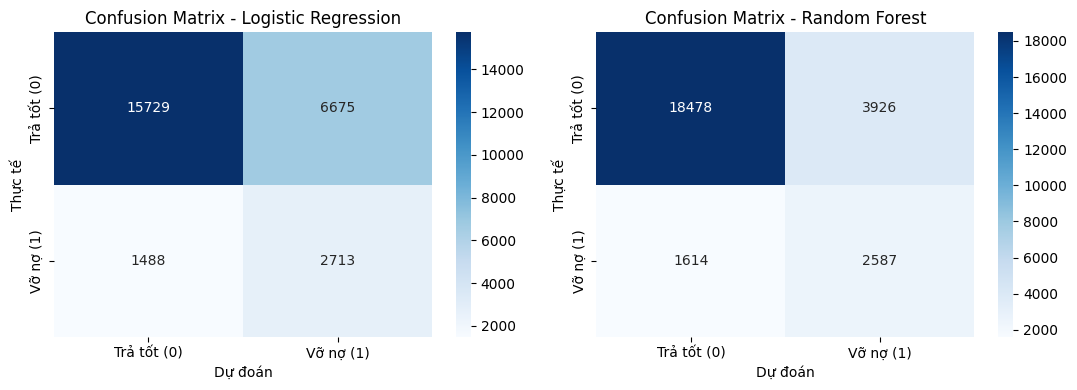

,Model,Accuracy,Precision,Recall,AUC
0,Logistic Regression,0.6932,0.2890,0.6458,0.7387
1,Random Forest,0.7918,0.3972,0.6158,0.7981


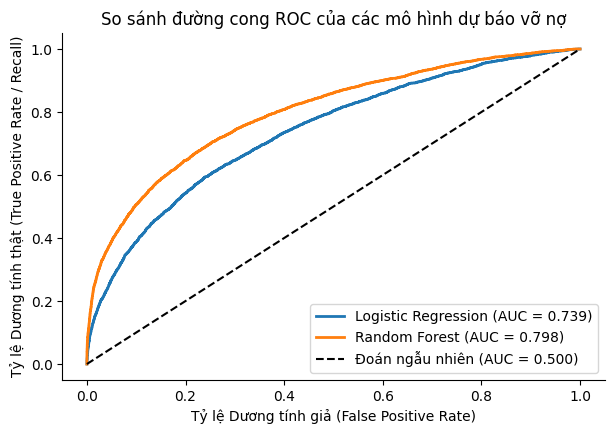

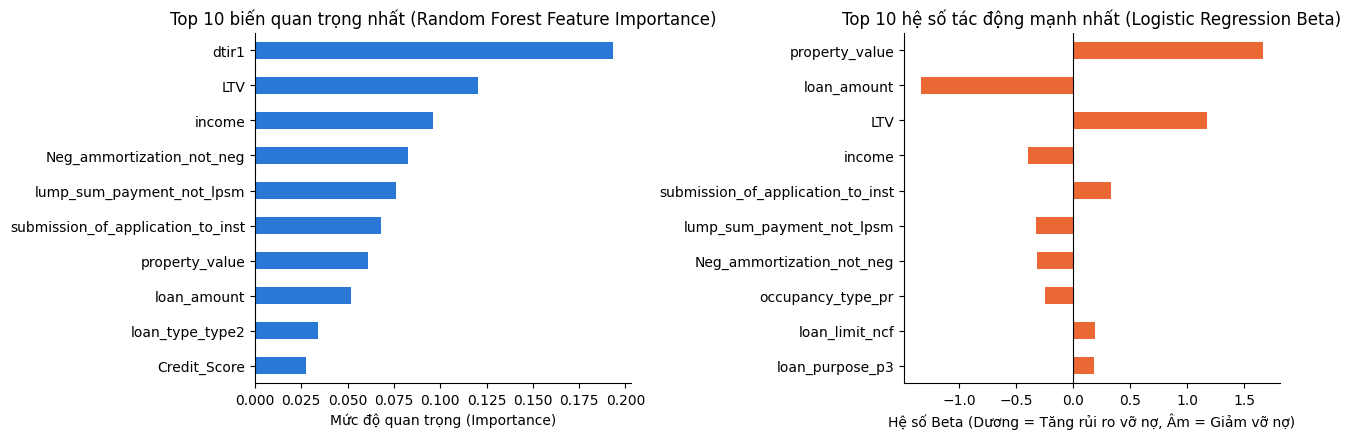

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, roc_curve, roc_auc_score

# 1. Tách biến độc lập (X) và biến mục tiêu (y) từ bảng model_data đã chuẩn bị ở mục 2.5
X = model_data.drop(columns=["Status"])
y = model_data["Status"]

# 2. Chia dữ liệu thành tập Train (80%) và Test (20%) có dùng stratify=y để giữ nguyên tỷ lệ lớp (Tuần 15 - Trang 12)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# 3. Chuẩn hóa StandardScaler: chỉ fit_transform trên X_train và transform trên X_test để tránh rò rỉ dữ liệu (Tuần 15 - Trang 5)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# 4. Khởi tạo mô hình Logistic Regression (Tuần 01 - Trang 28) và Random Forest Classifier (Tuần 14 & 15)
clf_models = {
    "Logistic Regression": LogisticRegression(max_iter=200, class_weight="balanced", random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=100, max_depth=12, class_weight="balanced", random_state=42, n_jobs=-1)
}

# 5. Huấn luyện mô hình, tính Accuracy, Precision, Recall, AUC và vẽ Ma trận nhầm lẫn (Tuần 15 - Trang 13)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
clf_results = []

for i, (name, model) in enumerate(clf_models.items()):
    model.fit(X_train_scaled, y_train)
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    auc = roc_auc_score(y_test, y_proba)
    clf_results.append({"Model": name, "Accuracy": round(acc, 4), "Precision": round(prec, 4), "Recall": round(rec, 4), "AUC": round(auc, 4)})

    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", ax=axes[i],
                xticklabels=["Trả tốt (0)", "Vỡ nợ (1)"], yticklabels=["Trả tốt (0)", "Vỡ nợ (1)"])
    axes[i].set_title(f"Confusion Matrix - {name}")
    axes[i].set_xlabel("Dự đoán")
    axes[i].set_ylabel("Thực tế")

plt.tight_layout()
plt.show()

df_clf_results = pd.DataFrame(clf_results)
display(df_clf_results)

# 6. Vẽ và so sánh đường cong ROC - AUC của 2 mô hình (Tuần 14 - Trang 21 & Tuần 15 - Trang 16)
plt.figure(figsize=(7, 4.5))
for name, model in clf_models.items():
    y_proba = model.predict_proba(X_test_scaled)[:, 1]
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc_score = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {auc_score:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Đoán ngẫu nhiên (AUC = 0.500)")
plt.xlabel("Tỷ lệ Dương tính giả (False Positive Rate)")
plt.ylabel("Tỷ lệ Dương tính thật (True Positive Rate / Recall)")
plt.title("So sánh đường cong ROC của các mô hình dự báo vỡ nợ")
plt.legend(loc="lower right")
plt.show()

# 7. Trích xuất Top 10 biến quan trọng nhất (Random Forest) và Hệ số Beta (Logistic Regression)
rf_imp = pd.Series(clf_models["Random Forest"].feature_importances_, index=X.columns).sort_values(ascending=True).tail(10)
lr_coef = pd.Series(clf_models["Logistic Regression"].coef_[0], index=X.columns)
lr_top = lr_coef.loc[lr_coef.abs().sort_values(ascending=True).tail(10).index]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
rf_imp.plot(kind="barh", color=BLUE, ax=axes[0])
axes[0].set_title("Top 10 biến quan trọng nhất (Random Forest Feature Importance)")
axes[0].set_xlabel("Mức độ quan trọng (Importance)")

lr_top.plot(kind="barh", color=ORANGE, ax=axes[1])
axes[1].axvline(0, color="black", lw=0.8)
axes[1].set_title("Top 10 hệ số tác động mạnh nhất (Logistic Regression Beta)")
axes[1].set_xlabel("Hệ số Beta (Dương = Tăng rủi ro vỡ nợ, Âm = Giảm vỡ nợ)")

plt.tight_layout()
plt.show()

**Giải thích code & Đối chiếu Slide bài giảng (Mục 3.9 - Mô hình Học máy có giám sát):**

| Dòng code / Hàm sử dụng | Giải thích tác dụng | Vị trí trong Slide môn học | Ghi chú (Trong/Ngoài slide) |
| :--- | :--- | :--- | :--- |
| `train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)` | Chia ngẫu nhiên dữ liệu thành 80% huấn luyện (`Train`) và 20% kiểm tra (`Test`), sử dụng `stratify=y` để đảm bảo tỷ lệ vỡ nợ ở tập Train và Test giống hệt nhau. | - **Tuần 15 (Thực hành 8):** Mục *Tiền xử lý dữ liệu bài toán phân loại* (Trang 12: `train_test_split(X_c, y_c, test_size=0.2, random_state=42, stratify=y_c)`). | **Có trong slide** (Giống 100% code mẫu Tuần 15) |
| `scaler.fit_transform(X_train)`<br>`scaler.transform(X_test)` | Chỉ học tham số chuẩn hóa (`mean`, `std`) từ tập `X_train` rồi biến đổi `X_test` để ngăn chặn rò rỉ thông tin từ tập kiểm tra. | - **Tuần 15 (Thực hành 8):** Mục *Chuẩn hóa dữ liệu* (Trang 5 giải thích chi tiết lý do chỉ `fit` trên tập Train để tránh Data Leakage). | **Có trong slide** |
| `LogisticRegression(max_iter=200, class_weight="balanced", ...)` | Khởi tạo mô hình Hồi quy Logistic có cân bằng trọng số lớp (`class_weight='balanced'`) cho dữ liệu ngân hàng mất cân bằng. | - **Tuần 01 (Bài giảng 1):** Bài toán Ngân hàng sử dụng đúng câu lệnh `LogisticRegression(max_iter=200, class_weight='balanced')` (Trang 28).<br>- **Tuần 14 & 15:** Hồi quy Logistic (Tuần 14 Trang 12; Tuần 15 Trang 13). | **Có trong slide** |
| `RandomForestClassifier(...)`<br>`accuracy_score`, `precision_score`, `recall_score`, `confusion_matrix` | Huấn luyện mô hình Rừng ngẫu nhiên, tính các chỉ số đánh giá trên tập Test và vẽ Ma trận nhầm lẫn (`Confusion Matrix`) bằng `sns.heatmap`. | - **Tuần 14 (Bài giảng 8):** Mục *Random Forest* & *Các chỉ số đánh giá nâng cao* (Trang 16, 20).<br>- **Tuần 15 (Thực hành 8):** Vòng lặp huấn luyện và vẽ `Confusion Matrix` (Trang 13). | **Có trong slide** |
| `roc_curve(y_test, y_proba)`<br>`roc_auc_score(y_test, y_proba)` | Tính tỷ lệ Dương tính thật (`TPR`), Dương tính giả (`FPR`) và diện tích dưới đường cong `AUC`, sau đó vẽ biểu đồ so sánh đường cong `ROC`. | - **Tuần 14 (Bài giảng 8):** Đường cong ROC và chỉ số AUC (Trang 20–21).<br>- **Tuần 15 (Thực hành 8):** Vẽ đường cong ROC so sánh các mô hình phân loại (Trang 14, 16). | **Có trong slide** |
| `model.feature_importances_`<br>`model.coef_[0]` | Trích xuất mức độ quan trọng của từng biến trong Random Forest và hệ số góc $\beta$ trong Logistic Regression để giải thích tác động kinh tế. | - **Tuần 08 (Bài giảng 5):** Trích xuất `model.feature_importances_` của Random Forest (Trang 7).<br>- **Tuần 14 (Bài giảng 8):** Trích xuất hệ số $\beta_1$ `model_log_reg.coef_[0]` (Trang 12). | **Có trong slide** |

**Nhận định kết quả Kiểm định Đa biến (Machine Learning):**
1. **Hiệu suất dự báo và sự đánh đổi giữa các chỉ số trên dữ liệu mất cân bằng:**
   - Khi sử dụng trọng số cân bằng lớp (`class_weight="balanced"`), **Logistic Regression** đạt **Recall cao hơn (`64.6%`)** so với **Random Forest (`61.6%`)**, nghĩa là Hồi quy Logistic bắt được tỷ lệ hồ sơ vỡ nợ cao hơn một chút nhưng phải đánh đổi bằng việc dự đoán nhầm nhiều hồ sơ tốt thành vỡ nợ (**Accuracy chỉ đạt `69.3%`** và **Precision đạt `28.9%`**).
   - Ngược lại, **Random Forest** vượt trội về khả năng phân tách tổng thể với **AUC = `0.798`** (so với `0.739` của Logistic Regression), **Accuracy đạt `79.2%`** và **Precision đạt `39.7%`**. Lý do là rủi ro vỡ nợ tăng vọt theo ngưỡng phi tuyến (`LTV > 100%`, `DTI > 50%`), nên thuật toán tập hợp cây quyết định (Random Forest) nắm bắt cấu trúc phi tuyến tốt hơn đường ranh giới tuyến tính.
2. **Đối chiếu đa biến củng cố kết quả kiểm chứng 6 giả thuyết H1 – H6:**
   - Trên biểu đồ **Feature Importance (Random Forest)**, các biến quan trọng nhất quyết định khả năng vỡ nợ lần lượt là **`dtir1`** (đứng đầu với mức độ quan trọng `~0.19` — khẳng định **H4**), **`LTV`** (đứng thứ 2 với `~0.12` — khẳng định **H3**), tiếp theo là nhóm biến quy mô tài chính/thu nhập (**`income`**, **`property_value`**, **`loan_amount`** — khẳng định **H2**) và hai hình thức trả nợ rủi ro là **`Neg_ammortization_not_neg`** (hạng 4) cùng **`lump_sum_payment_not_lpsm`** (hạng 5, `~0.076` — khẳng định **H6**).
   - Trên biểu đồ **Hệ số Beta (Logistic Regression)**, hai biến đứng đầu là **`property_value`** (dương mạnh, khoảng `+1.65`) và **`loan_amount`** (âm mạnh, khoảng `-1.35`), đi kèm hệ số dương của **`LTV`**. Hiện tượng `property_value` và `loan_amount` có hệ số lớn nhưng ngược dấu nhau là hệ quả quen thuộc của **đa cộng tuyến (multicollinearity)** khi đặt cả 3 biến có quan hệ công thức ($\text{LTV} = \text{loan\_amount} / \text{property\_value}$) vào cùng một phương trình tuyến tính; do đó không nên diễn giải tách rời tác động kinh tế riêng lẻ của từng biến này. Bên cạnh đó, các biến có ý nghĩa kinh tế rõ ràng làm giảm rủi ro vỡ nợ (hệ số $\beta$ âm) là **`lump_sum_payment_not_lpsm`**, **`Neg_ammortization_not_neg`** và **`income`**.
   - Đối với biến **`Credit_Score`**, hệ số $\beta$ không nằm trong nhóm tác động mạnh của Logistic Regression và chỉ xếp ở vị trí cuối cùng trong Top 10 của Random Forest (mức độ quan trọng rất nhỏ, khoảng `0.028` — chủ yếu do cây quyết định dùng các biến liên tục để chia nhánh phụ), phù hợp với kết luận **bác bỏ giả thuyết H5**.

---
# Giai đoạn 4 — Tổng kết, Khuyến nghị thực tiễn và Hướng phát triển

## 4.1. Các phát hiện chính (Main findings)

1. **Phát hiện và loại bỏ rò rỉ dữ liệu (Data Leakage) nghiêm trọng:** Cột `Interest_rate_spread` (cùng `rate_of_interest`, `Upfront_charges`) bị bỏ trống ở **99.5% – 100.0%** các khoản vay vỡ nợ, khiến việc đoán mò theo ô trống cũng trùng khớp `100.0%` với nhãn vỡ nợ. Tương tự, mã `credit_type = EQUI` gắn với **`99.99%`** vỡ nợ. Việc loại bỏ 4 cột này, lọc các hồ sơ thiếu `LTV` và 548 dòng lỗi nhập liệu là bước quyết định để tập phân tích (**133,024 hồ sơ**, tỷ lệ vỡ nợ trung bình **`15.8%`**) phản ánh đúng bản chất tài chính.
2. **Tỷ lệ nợ trên thu nhập (`dtir1`) và tỷ lệ vay trên tài sản (`LTV`) là hai tín hiệu cảnh báo rủi ro quan trọng nhất:** Trong mô hình Random Forest, `dtir1` đứng số 1 (`~0.19`) và `LTV` đứng số 2 (`~0.12`) về mức độ quan trọng (`Feature Importance`). Xét theo ngưỡng, những khoản vay vượt quá giá trị tài sản thế chấp (`LTV > 100%`) có tỷ lệ vỡ nợ lên tới **65.0%**, và nhóm khách hàng có gánh nặng nợ cao (`DTI > 50%`) có tỷ lệ vỡ nợ vọt lên **42.7%**.
3. **Cấu trúc trả nợ rủi ro làm tăng vọt khả năng vỡ nợ:** Khoản vay trả gốc một lần cuối kỳ (`lump_sum_payment = lpsm`) có tỷ lệ vỡ nợ **65.5%** (so với `15.0%` ở nhóm trả góp thường), và khoản vay khấu hao âm (`Neg_ammortization = neg_amm`) có tỷ lệ vỡ nợ **32.7%** (so với `14.0%` ở nhóm thường).
4. **Thu nhập càng cao thì tỷ lệ vỡ nợ càng giảm đều:** Tỷ lệ vỡ nợ giảm liên tục từ **25.2%** ở nhóm thu nhập Rất thấp (trung vị `2,700`) xuống **16.9%** (Thấp), **13.1%** (Trung bình), **11.8%** (Cao) và chỉ còn **11.7%** ở nhóm Rất cao (trung vị `12,000`). Xét theo độ tuổi, rủi ro cao tập trung ở hai đầu: nhóm rất trẻ `<25` tuổi (**19.7%**) và nhóm lớn tuổi `>74` tuổi (**19.5%**).
5. **Điểm tín dụng (`Credit_Score`) trong bộ dữ liệu này không có tác dụng phân loại rủi ro:** Do dữ liệu cột này phân bố đều từ `500` đến `900` như số ngẫu nhiên, tỷ lệ vỡ nợ giữa các mức điểm gần như bằng nhau (**15.4% – 16.3%**) và hai hộp phân phối Boxplot giữa nhóm vỡ nợ và trả tốt trùng khít nhau.

## 4.2. Khuyến nghị thực tiễn cho ngân hàng (Recommendations)

* **Kiểm soát chặt trần tỷ lệ vay trên giá trị tài sản (`LTV`):** Hạn chế tối đa việc cấp tín dụng cho các hồ sơ có `LTV > 100%` (vỡ nợ `65.0%`); với các hồ sơ có `LTV` trong vùng `80–100%` (vỡ nợ `18.0% – 19.2%`), bắt buộc yêu cầu khách hàng bổ sung vốn tự có hoặc mua bảo hiểm khoản vay thế chấp.
* **Áp dụng ngưỡng kiểm soát tỷ lệ nợ trên thu nhập (`DTI`):** Duy trì vùng ưu tiên phê duyệt ở mức `DTI` từ `20–43%` (vỡ nợ thấp `12.0% – 12.7%`), theo dõi sát nhóm bắt đầu vượt trung bình (`DTI 43–50%`, vỡ nợ `16.5%`) và **áp dụng ngưỡng chặn/siết chặt phê duyệt đối với các hồ sơ có `DTI > 50%`** (nhóm có tỷ lệ vỡ nợ vọt lên `42.7%`).
* **Siết chặt điều kiện đối với sản phẩm trả gốc một lần (`lpsm`) và khấu hao âm (`neg_amm`):** Chỉ cung cấp các gói vay này cho khách hàng có dòng tiền dự phòng rõ ràng, thu nhập cao và tỷ lệ `LTV` thấp.
* **Thẩm định kỹ các hồ sơ khai báo `DTI ≤ 20%`, khách hàng `<25` tuổi hoặc `income = 0`:** Do nhóm `DTI ≤ 20%` có tỷ lệ vỡ nợ cao bất thường (`21.0%`) và nhóm `<25` tuổi vỡ nợ tới `19.7%`, ngân hàng cần đối chiếu chứng từ thu nhập và dư nợ thực tế tại trung tâm tín dụng để tránh khách hàng khai thiếu nợ hiện tại.
* **Cải tiến quy trình kỹ thuật dữ liệu (Data Engineering):** Bắt buộc lưu trữ đầy đủ thông tin lãi suất (`rate_of_interest`, `Interest_rate_spread`) và chi phí trả trước (`Upfront_charges`) ngay tại thời điểm giải ngân cho **mọi** hồ sơ, tránh tình trạng chỉ cập nhật cho các khoản vay trả nợ tốt gây rò rỉ dữ liệu.

## 4.3. Hạn chế của dữ liệu và Hướng phát triển (Limitations & Future work)

**Hạn chế của dữ liệu (Limitations):**
* **Thiếu từ điển dữ liệu chính thức:** Các mã viết tắt như `p1`–`p4` (mục đích vay) hay `type1`–`type3` (loại khoản vay) không có tài liệu giải thích chi tiết từ đơn vị cung cấp.
* **Độ lệch mẫu sau khi lọc hồ sơ thiếu `LTV` và dòng lỗi:** Việc loại bỏ 15,098 hồ sơ thiếu `LTV` và 548 dòng lỗi nhập liệu (đa số là hồ sơ vỡ nợ bị thiếu hàng loạt thông tin) làm tỷ lệ vỡ nợ của tập phân tích giảm từ `24.6%` xuống `15.8%`.
* **Dữ liệu chỉ gói gọn trong năm 2019 và biến `Credit_Score` có dấu hiệu tổng hợp nhân tạo:** Không thể phân tích xu hướng biến động theo thời gian hoặc chu kỳ kinh tế vĩ mô.
* **Điền khuyết trước khi chia Train/Test:** Giá trị trung vị và mode dùng để điền ô trống được tính trên toàn bộ tập dữ liệu trước khi chia Train/Test, nên có thể gây rò rỉ thông tin ở mức nhẹ sang tập kiểm tra.

**Hướng phát triển tiếp theo (Future work):**
* **Khắc phục đa cộng tuyến và tinh chỉnh đặc trưng (Feature Engineering):** Loại bỏ bớt biến dư thừa trong cụm cộng tuyến (`loan_amount`, `property_value`, `LTV`) khi đưa vào mô hình tuyến tính, đồng thời tạo thêm các biến tương tác phi tuyến (như kết hợp `LTV > 90%` và `DTI > 50%` hoặc tỷ lệ `loan_amount / income`).
* **Thử nghiệm các thuật toán Boosting và tối ưu ngưỡng cắt (Threshold Tuning):** Mở rộng sang các mô hình mạnh hơn cho dữ liệu bảng như XGBoost, LightGBM và điều chỉnh ngưỡng xác suất dự báo (thay vì mặc định `0.5`) dựa trên ma trận chi phí thiệt hại tài chính thực tế của ngân hàng.
* **Thu thập dữ liệu chuỗi thời gian (Panel/Time-series data):** Kết hợp dữ liệu lịch sử trả nợ qua nhiều năm và các chỉ số kinh tế vĩ mô (lãi suất thị trường, tỷ lệ thất nghiệp, lạm phát) để xây dựng mô hình dự báo sớm rủi ro tín dụng theo chu kỳ kinh tế.